# Исследование рынка общественного питания Москвы
## Цель и задачи 

**Цель:** Провести исследовательский анализ данных рынка общественного питания Москвы с выявлением подходящего инвесторам  из фонда Shut Up and Take My Money места открыть заведение общественного питания.

**Задачи:**
1. Загрузить данные и познакомиться с их содержимым.
2. Провести предобработку данных.
3. Провести исследовательский анализ данных.
4. Сформулировать выводы по проведённому анализу.

## Данные

Для анализа поступили данные с заведениями общественного питания Москвы, составленный на основе данных сервисов Яндекс Карты и Яндекс Бизнес за лето 2022 года. Информация, размещённая в сервисе Яндекс Бизнес, могла быть добавлена пользователями или найдена в общедоступных источниках. Она носит исключительно справочный характер. Данные состоят из двух датасетов:
- `rest_info.csv` - информацию о заведениях общественного питания;
- `rest_price.csv` - информацию о среднем чеке в заведениях общественного питания;

### Описание датасета `rest_info.csv`

- `name` — название заведения;
- `address` — адрес заведения;
- `district` — административный район, в котором находится заведение, например Центральный административный округ;
- `category` — категория заведения, например «кафе», «пиццерия» или «кофейня»;
- `hours` — информация о днях и часах работы;
- `rating` — рейтинг заведения по оценкам пользователей в Яндекс Картах (высшая оценка — 5.0);
- `chain` — число, выраженное 0 или 1, которое показывает, является ли заведение сетевым (для маленьких сетей могут встречаться ошибки):
    - 0 — заведение не является сетевым;
    - 1 — заведение является сетевым.
- `seats` — количество посадочных мест.

### Описание датасета `rest_price.csv`

- `price` — категория цен в заведении, например «средние», «ниже среднего», «выше среднего» и так далее;
- `avg_bill` — хранит среднюю стоимость заказа в виде диапазона, например:
    - «Средний счёт: 1000–1500 ₽»;
    - «Цена чашки капучино: 130–220 ₽»;
    - «Цена бокала пива: 400–600 ₽».
    - и так далее;
- `middle_avg_bill` — число с оценкой среднего чека, которое указано только для значений из столбца avg_bill, начинающихся с подстроки «Средний счёт»:
    - Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений.
    - Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число.
    - Если значения нет или оно не начинается с подстроки «Средний счёт», то в столбец ничего не войдёт.
- `middle_coffee_cup` — число с оценкой одной чашки капучино, которое указано только для значений из столбца avg_bill, начинающихся с подстроки «Цена одной чашки капучино»:
    - Если в строке указан ценовой диапазон из двух значений, в столбец войдёт медиана этих двух значений.
    - Если в строке указано одно число — цена без диапазона, то в столбец войдёт это число.
    - Если значения нет или оно не начинается с подстроки «Цена одной чашки капучино», то в столбец ничего не войдёт.

## Структура проекта

1. Загрузка данных и знакомство с ними.
2. Предобработка данных.
3. Исследовательский анализ данных.
4. Итоговые выводы.

---

## 1. Загрузка данных и знакомство с ними
Начнём с загрузки библиотек и датасетов `rest_info.csv` и `rest_price.csv`. Будем использовать `pandas` и библиотеки визуализации данных `matplotlib` и `seaborn`, а также `phik` для построения матрицы корреляции. Данные датасетов сохраним в двух переменных: `info_df` и `price_df`.

In [54]:
# Импортируем библиотеки
import pandas as pd

# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt
import seaborn as sns

# Загружаем библиотеку для расчёта коэффициента корреляции phi_k
from phik import phik_matrix

import warnings
warnings.filterwarnings('ignore')

In [20]:
# Выгружаем данные в переменные info_df и price_df
info_df = pd.read_csv('rest_info.csv')
price_df = pd.read_csv('rest_price.csv')

Познакомимся с данными датасета `rest_info.csv` — выведем информацию о датафрейме методом `info()`, а первые строки методом `head()`:

In [21]:
# Выводим информацию о датафрейме info_df
info_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 9 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        8406 non-null   object 
 1   name      8406 non-null   object 
 2   category  8406 non-null   object 
 3   address   8406 non-null   object 
 4   district  8406 non-null   object 
 5   hours     7870 non-null   object 
 6   rating    8406 non-null   float64
 7   chain     8406 non-null   int64  
 8   seats     4795 non-null   float64
dtypes: float64(2), int64(1), object(6)
memory usage: 591.2+ KB


In [22]:
# Выводим первые строки датафрейма info_df на экран
info_df.head()

,id,name,category,address,district,hours,rating,chain,seats
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0


Датасет 'rest_info.csv' содержит 9 столбцов и 8406 строк, в котором представлена информация о заведениях общественного питания г.Москвы.

После первичного анализа данных можно сделать следующие выводы:

* Названия столбцов корректны, значения в столбцах соответствуют своему описанию.
* Пропуски содержатся в 2х столбцах: `hours` и `seats`, далее исследуем детальнее этот момент.
* Столбец `chain` имеет тип данных `int64`. Данные в этом столбце демонстрируют, является ли заведение сетевым и содержат значения 1 или 0 — размерность этих данных можно оптимизировать. Столбец `rating` содержит данные с рейтингом заведения по оценкам пользователей в Яндекс Картах и тип данных float64 является для него абсолютно точным. Что касается столбца `seats`, в нем указано количество посадочных мест, которое не может быть дробным и тип данным float64 присвоен данному столбцу из-за пропусков. Столбцы `id` (не указан в описании, но это не критично, видимо, уникальный идентификатор заведения), `name`, `category`, `address`, `district`, `hours` содержат текстовую информацию и тип данных 'object' является для них корректным.
* Из особенностей важно отметить: в столбце `chain` - для маленьких сетей могут встречаться ошибки. В столбце `hours` встречаются разные форматы записи (ежедневно, 10:00–22:00; пн,ср,чт,пт,сб,вс 12:00–03:00).

Теперь познакомимся с данными датасета 'rest_price.csv'.

In [23]:
# Выводим информацию о датафрейме price_df
price_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4058 entries, 0 to 4057
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 4058 non-null   object 
 1   price              3315 non-null   object 
 2   avg_bill           3816 non-null   object 
 3   middle_avg_bill    3149 non-null   float64
 4   middle_coffee_cup  535 non-null    float64
dtypes: float64(2), object(3)
memory usage: 158.6+ KB


In [24]:
# Выводим первые строки датафрейма на экран
price_df.head()

,id,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,045780ada3474c57a2112e505d74b633,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
1,1070b6b59144425896c65889347fcff6,средние,Средний счёт:от 1000 ₽,1000.0,NaN
2,03ac7cd772104f65b58b349dc59f03ee,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
3,a163aada139c4c7f87b0b1c0b466a50f,средние,Средний счёт:400–600 ₽,500.0,NaN
4,8a343546b24e4a499ad96eb7d0797a8a,средние,NaN,NaN,NaN


Датасет 'rest_price.csv' содержит 5 столбцов и 4058 строк.

После первичного анализа данных можно сделать следующие выводы:

Названия столбцов корректны, значения в столбцах соответствуют своему описанию. Пропуски (весьма значительные) содержатся во всех столбцах, кроме 'id'(очевидно, добавлен для связки с основным датасетом), что разберем детальнее чуть ниже. В столбцах 'id', 'price', 'avg_bill' содержится текстовая информация, тип данных object присвоен корректно. В столбцах 'middle_avg_bill' и 'middle_coffee_cup' содержатся числовые данные, причем целые числа, но из-за пропусков им присвоен тип float64. Разберем это позднее. Важные особенности: в столбце avg_bill есть разные форматы (Средний счёт:1500–1600 ₽; Цена чашки капучино:155–185 ₽; Средний счёт:от 1000 ₽; Средний счёт:199 ₽). В столбце price есть пропуски, даже при наличии данных о среднем чеке в столбце avg_bill. Количество записей в rest_price.csv (4058) меньше, чем в rest_info.csv (8406). Это значит, что не для всех заведений есть информация о ценах. При объединении датасетов через id часть записей останется без ценовых данных (это нормально, но нужно будет учитывать при анализе)

Объединим датасеты в один, чтобы удобнее было работать с данными в процессе анализа.

In [25]:
# Соединяем данные в единый датафрейм df
df = pd.merge(info_df, price_df, on='id', how='left')

In [26]:
# Выводим информацию об объединенном датафрейме
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8406 entries, 0 to 8405
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 8406 non-null   object 
 1   name               8406 non-null   object 
 2   category           8406 non-null   object 
 3   address            8406 non-null   object 
 4   district           8406 non-null   object 
 5   hours              7870 non-null   object 
 6   rating             8406 non-null   float64
 7   chain              8406 non-null   int64  
 8   seats              4795 non-null   float64
 9   price              3315 non-null   object 
 10  avg_bill           3816 non-null   object 
 11  middle_avg_bill    3149 non-null   float64
 12  middle_coffee_cup  535 non-null    float64
dtypes: float64(4), int64(1), object(8)
memory usage: 853.9+ KB


In [27]:
# Выведем первые строки объединенного датафрейма на экран
df.head()

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
0,0c3e3439a8c64ea5bf6ecd6ca6ae19f0,WoWфли,кафе,"Москва, улица Дыбенко, 7/1",Северный административный округ,"ежедневно, 10:00–22:00",5.0,0,NaN,NaN,NaN,NaN,NaN
1,045780ada3474c57a2112e505d74b633,Четыре комнаты,ресторан,"Москва, улица Дыбенко, 36, корп. 1",Северный административный округ,"ежедневно, 10:00–22:00",4.5,0,4.0,выше среднего,Средний счёт:1500–1600 ₽,1550.0,NaN
2,1070b6b59144425896c65889347fcff6,Хазри,кафе,"Москва, Клязьминская улица, 15",Северный административный округ,"пн-чт 11:00–02:00; пт,сб 11:00–05:00; вс 11:00...",4.6,0,45.0,средние,Средний счёт:от 1000 ₽,1000.0,NaN
3,03ac7cd772104f65b58b349dc59f03ee,Dormouse Coffee Shop,кофейня,"Москва, улица Маршала Федоренко, 12",Северный административный округ,"ежедневно, 09:00–22:00",5.0,0,NaN,NaN,Цена чашки капучино:155–185 ₽,NaN,170.0
4,a163aada139c4c7f87b0b1c0b466a50f,Иль Марко,пиццерия,"Москва, Правобережная улица, 1Б",Северный административный округ,"ежедневно, 10:00–22:00",5.0,1,148.0,средние,Средний счёт:400–600 ₽,500.0,NaN


Датафрейм готов к последующему анализу.

## 2. Предобработка данных

### Оптимизируем типы данных

Проведем оптимизацию данных в столбце `chain`. Для оптимизации будем использовать метод `pd.to_numeric` с аргументом `downcast='integer'`:

In [28]:
# Оптимизируем целочисленный тип данных в столбце chain
df['chain'] = pd.to_numeric(df['chain'], downcast='integer')

In [29]:
# Проверим результат с помощью метода dtype
df['chain'].dtype

dtype('int8')

Тип данных был успешно оптимизирован с понижением размерности целочисленных данных.

In [30]:
# Оптимизируем вещественный тип данных в столбцах 'rating','middle_avg_bill','middle_coffee_cup','seats'
for column in ['rating','middle_avg_bill','middle_coffee_cup','seats']:
    df[column] = pd.to_numeric(df[column], downcast='float')

In [31]:
df[['rating','middle_avg_bill','middle_coffee_cup','seats']].dtypes

rating               float32
middle_avg_bill      float32
middle_coffee_cup    float32
seats                float32
dtype: object

Далее переходим к проверке пропусков.

### Проверяем наличие пропусков в данных

При первичном знакомстве с данными мы обнаружили большое количество пропусков. Теперь узнаем точное абсолютное и относительное количество пропусков в каждом столбце.

In [32]:
# Применим метод isna() к нашему датафрейму 
df.isna().sum().sort_values(ascending=False)

middle_coffee_cup    7871
middle_avg_bill      5257
price                5091
avg_bill             4590
seats                3611
hours                 536
id                      0
name                    0
category                0
address                 0
district                0
rating                  0
chain                   0
dtype: int64

In [33]:
# Посчитаем количество пропусков в относительном значении в каждом столбце
df.isna().mean().sort_values(ascending=False)

middle_coffee_cup    0.936355
middle_avg_bill      0.625387
price                0.605639
avg_bill             0.546039
seats                0.429574
hours                0.063764
id                   0.000000
name                 0.000000
category             0.000000
address              0.000000
district             0.000000
rating               0.000000
chain                0.000000
dtype: float64

**Промежуточный вывод по результатам анализа пропусков в данных**

* Общая картина пропусков

В объединённом датафрейме из 13 столбцов 6 столбцов содержат пропуски, при этом степень их заполненности сильно варьируется:

 


| Столбец | Кол-во пропусков | Доля пропусков | Степень заполненности |
|---------|------------------|----------------|----------------------|
| middle_coffee_cup | 7 871 | 93.6% | Крайне низкая |
| middle_avg_bill | 5 257 | 62.5% | Низкая |
| price | 5 091 | 60.6% | Низкая |
| avg_bill | 4 590 | 54.6% | Средняя |
| seats | 3 611 | 43.0% | Средняя |
| hours | 536 | 6.4% | Высокая |

* Анализ пропусков по группам столбцов

    * Ценовые данные (столбцы из rest_price.csv)

Все четыре столбца из ценового датасета имеют значительные пропуски:

Только 46% заведений (3 816 из 8 406) имеют информацию о среднем чеке (avg_bill).
Только 37.5% заведений имеют числовую оценку среднего чека (middle_avg_bill).
Категория цен (price) заполнена лишь у 39.4% заведений.
Цена капучино (middle_coffee_cup) присутствует только у 6.4% заведений.

Гипотеза появления пропусков:

Ценовая информация собиралась не для всех заведений (возможно, данные отсутствовали в открытых источниках).
middle_coffee_cup заполняется только для заведений, где в avg_bill указана цена капучино (что характерно для кофеен и кафе, а не для ресторанов или баров).
middle_avg_bill заполняется только для записей, начинающихся с "Средний счёт", что составляет не все записи с ценовой информацией.

* Посадочные места (seats)

43% заведений не имеют информации о количестве посадочных мест.

Гипотеза появления пропусков:

Данные о вместимости могли отсутствовать в публичных источниках.
Возможно, для некоторых заведений (например, фудтраки, киоски, точки без посадочных мест) информация неактуальна.

* Время работы (hours)

6.4% заведений не имеют информации о режиме работы — это наименьшая доля пропусков среди всех проблемных столбцов.

Гипотеза появления пропусков:

Данные могли отсутствовать в источниках для небольшой части заведений.
Возможно, это новые заведения, ещё не добавившие информацию.

* Столбцы без пропусков

Следующие столбцы заполнены полностью (100%):

id, name, category, address, district, rating, chain
Это хорошо, так как эти столбцы являются ключевыми для идентификации и категоризации заведений.

* Ключевые наблюдения

Ценовые данные доступны менее чем для половины заведений — это ограничивает возможность анализа связи цен с другими параметрами.
Информация о посадочных местах отсутствует у значительной части заведений — потребуется аккуратный подход к анализу вместимости.
Нет пропусков в ключевых идентификационных и категориальных столбцах — это позволяет проводить группировки и категориальный анализ без потери данных.



***Данные имеют значительные пропуски в ценовых столбцах (более 50%), что связано с особенностями сбора информации — не для всех заведений удалось найти ценовые данные в открытых источниках. Пропуски в seats (43%) также существенны. При этом ключевые идентификационные и категориальные данные заполнены полностью, что позволяет проводить полноценный анализ структуры рынка. На данном этапе оставим пропуски как есть. Удалять строки с таким большим количеством пропусков точно не стоит. Но и на что заменить их пока сложно сказать.***

###  Явные и неявные дубликаты в данных
Проверим данные на наличие явных и неявных дубликатов.

In [34]:
# Проверяем полные дубликаты
df.duplicated().sum()

0

В датафреймах нет полных дубликатов строк. Проверим неявные дубликаты, начнем со значений по 'id' заведений, каждый 'id' должны быть уникальными.

In [35]:
# Проверка дубликатов по id 
df['id'].nunique()

8406

Все id являются уникальными.

Также проверим столбцы с названием и адресом заведений.

Для начала нормализуем данные в столбце с названием заведений:

In [36]:
df['name'] = df['name'].str.lower()

Далее проверяем, есть ли совпадения одновременно в столбцах 'name' и 'address':

In [37]:
df.duplicated(subset=['name', 'address'], keep=False).sum()

6

проверим данные дубликаты:

In [38]:
df.loc[df.duplicated(subset=['name', 'address'], keep=False)]

,id,name,category,address,district,hours,rating,chain,seats,price,avg_bill,middle_avg_bill,middle_coffee_cup
1430,62608690e9cc464fbcd980cfd552e334,more poke,ресторан,"Москва, Волоколамское шоссе, 11, стр. 2",Северный административный округ,"ежедневно, 09:00–21:00",4.2,0,188.0,NaN,NaN,NaN,NaN
1511,a69f018d5c064873a3b491b0121bc1b4,more poke,ресторан,"Москва, Волоколамское шоссе, 11, стр. 2",Северный административный округ,"пн-чт 09:00–18:00; пт,сб 09:00–21:00; вс 09:00...",4.2,1,188.0,NaN,NaN,NaN,NaN
2211,c6ef39ae8a8c483d8f9a6531bc386a2c,раковарня клешни и хвосты,ресторан,"Москва, проспект Мира, 118",Северо-Восточный административный округ,"ежедневно, 12:00–00:00",4.4,0,150.0,NaN,NaN,NaN,NaN
2420,aba1de7ad7d64ac0a3f8684bda29d905,раковарня клешни и хвосты,"бар,паб","Москва, проспект Мира, 118",Северо-Восточный административный округ,"пн-чт 12:00–00:00; пт,сб 12:00–01:00; вс 12:00...",4.4,1,150.0,NaN,NaN,NaN,NaN
3091,3c2a73ea79a04be48858fab3685f2f37,хлеб да выпечка,булочная,"Москва, Ярцевская улица, 19",Западный административный округ,"ежедневно, 09:00–22:00",4.1,1,276.0,NaN,NaN,NaN,NaN
3109,d3116844e4e048f99614eb30be3214e0,хлеб да выпечка,кафе,"Москва, Ярцевская улица, 19",Западный административный округ,NaN,4.1,0,276.0,NaN,NaN,NaN,NaN


Ресторан `more poke` похоже внесли 2 раза с разной информацией по часам работы, в одном случае относится к сети в другом нет. `раковарня клешни и хвосты` в одном случае указан как ресторан, во втором - бар, паб, в одном случае относится к сети в другом нет, также разные часы работы. `хлеб да выпечка` в одном случае указан как булочная, в другом кафе,в одном случае относится к сети в другом нет, в одном случае указаны часы работы, в другом эта информация отсутствует. Несмотря на эти различия, похоже, что это дубликаты и не будет ошибкой их удалить.

In [39]:
df = df.drop_duplicates(subset=['name', 'address']) 

In [40]:
df.shape[0]

8403

Удалили 3 дубликата.

In [41]:
# Проверяем уникальные значения в  столбцах 'category', 'district', 'price'
for column in ['category', 'district', 'price']:
    print(f'Уникальные значения в столбце {column}:')
    print(df[column].sort_values().unique())
    print()

Уникальные значения в столбце category:
['бар,паб' 'булочная' 'быстрое питание' 'кафе' 'кофейня' 'пиццерия'
 'ресторан' 'столовая']

Уникальные значения в столбце district:
['Восточный административный округ' 'Западный административный округ'
 'Северный административный округ'
 'Северо-Восточный административный округ'
 'Северо-Западный административный округ'
 'Центральный административный округ'
 'Юго-Восточный административный округ'
 'Юго-Западный административный округ' 'Южный административный округ']

Уникальные значения в столбце price:
['высокие' 'выше среднего' 'низкие' 'средние' nan]



**Промежуточный вывод по результатам проверки дубликатов**

* Явные дубликаты:
- Полных дубликатов строк не обнаружено (0 дубликатов).
- Дубликатов по уникальному идентификатору 'id' не обнаружено (0 дубликатов).
- Совместных дубликатов по паре 'name' + 'address' обнаружено и удалено 3. 


* Проверка категориальных столбцов:
    - 'category': 8 уникальных категорий. Все значения корректны, 
      нормализация не требуется.
    -'district': 9 административных округов. Все значения корректны,
      нормализация не требуется.
    - 'price': 4 ценовые категории. Все значения корректны,
      нормализация не требуется.


Для дальнейшей работы создадим столбец is_24_7 с обозначением того, что заведение работает ежедневно и круглосуточно, то есть 24/7:

логическое значение True — если заведение работает ежедневно и круглосуточно;
логическое значение False — в противоположном случае.

In [42]:
# Проверим строки содержащие слово 'ежедневно'
df['hours'][df['hours'].str.contains('ежедневно', case=False, na=False)]   

0         ежедневно, 10:00–22:00
1         ежедневно, 10:00–22:00
3         ежедневно, 09:00–22:00
4         ежедневно, 10:00–22:00
5         ежедневно, 10:00–23:00
                  ...           
8401      ежедневно, 09:00–02:00
8402      ежедневно, 08:00–22:00
8403    ежедневно, круглосуточно
8404    ежедневно, круглосуточно
8405    ежедневно, круглосуточно
Name: hours, Length: 5020, dtype: object

Круглосуточные заведения содержат в себе 2 слова ежедневно и круглосуточно. Напишем функцию. Для отбора круглосуточных заведений будет достаточно указать ключевое слово круглосуточно:

In [43]:
def is_24_7(hours_str):
  
    # Функция определяет, работает ли заведение ежедневно и круглосуточно (24/7).
    # True — если в строке есть оба слова: 'ежедневно' и 'круглосуточно'.
   
    if pd.isna(hours_str):
        return False
    
    hours_str = str(hours_str).strip().lower()
    
    # Проверяем наличие обоих ключевых слов
    if 'ежедневно' in hours_str and 'круглосуточно' in hours_str:
        return True
    
    return False 

    

In [44]:
# Создаём столбец is_24_7
df['is_24_7'] = df['hours'].apply(is_24_7)

# Проверяем результат
display(df['is_24_7'].value_counts())
print(f"\nДоля круглосуточных заведений: {df['is_24_7'].sum()/len(df)*100:.2f}%")

is_24_7
False    7673
True      730
Name: count, dtype: int64


Доля круглосуточных заведений: 8.69%


In [45]:
# Выведем примеры круглосуточных заведений для проверки
df[df['is_24_7'] == True][['name', 'category', 'hours', 'is_24_7']].head()

,name,category,hours,is_24_7
10,great room bar,"бар,паб","ежедневно, круглосуточно",True
17,чайхана беш-бармак,ресторан,"ежедневно, круглосуточно",True
19,пекарня,булочная,"ежедневно, круглосуточно",True
24,drive café,кафе,"ежедневно, круглосуточно",True
49,2u-ту-ю,пиццерия,"ежедневно, круглосуточно",True


Количество круглосуточных заведений: 730 (8.69% от всех заведений)

**Промежуточный вывод по первичному анализу и предобработке данных**

**1. Общая информация о данных**

| Параметр | Значение |
|----------|----------|
| Размер исходного объединённого датасета | 8 406 строк × 13 столбцов |
| Размер после всех преобразований | 8 403 строки × 14 столбцов |
| Удалено строк | 3 (0.04%) |

**Описание данных:**  
Датасет содержит информацию о заведениях общественного питания Москвы на основе данных сервисов Яндекс Карты и Яндекс Бизнес за лето 2022 года. Включает характеристики заведений: название, адрес, район, категория, режим работы, рейтинг, статус сети, количество посадочных мест, ценовая категория, средний чек и цена чашки капучино.


**2. Типы данных**

| Выполненное преобразование | Столбцы |
|---------------------------|---------|
| Понижение размерности целочисленных данных до int8 | `chain` |
| Понижение размерности вещественных данных до float32 | `rating`, `middle_avg_bill`, `middle_coffee_cup`, `seats` |
| Преобразование логического типа | `is_24_7` (bool) |

**Результат:** все столбцы имеют корректные типы данных для дальнейшего анализа.



**3. Пропуски**

**До обработки:**

| Столбец | Кол-во пропусков | Доля пропусков |
|---------|------------------|----------------|
| `middle_coffee_cup` | 7 871 | 93.6% |
| `middle_avg_bill` | 5 257 | 62.5% |
| `price` | 5 091 | 60.6% |
| `avg_bill` | 4 590 | 54.6% |
| `seats` | 3 611 | 43.0% |
| `hours` | 536 | 6.4% |

**Метод обработки:** пропуски не заполнялись и не удалялись, так как:
- Удаление строк с пропусками привело бы к потере более 50% данных
- Заполнение пропусков могло бы исказить реальную картину
- Пропуски в ценовых данных связаны с особенностями сбора информации из открытых источников

**После обработки:** пропуски сохранены в исходном виде для использования в анализе с учётом их ограничений.

---

**4. Дубликаты**

| Тип дубликатов | Количество | Метод обработки |
|----------------|------------|-----------------|
| Полные дубликаты строк | 0 | Не требовалось |
| Дубликаты по `id` | 0 | Не требовалось |
| Неявные дубликаты по паре `name` + `address` | 3 | Удалены |

**Результат:** после удаления 3 неявных дубликатов в датасете не осталось дублирующихся записей.

---

**5. Создание новых признаков**

| Новый столбец | Описание |
|---------------|----------|
| `is_24_7` | Логический признак (bool): `True` — заведение работает ежедневно и круглосуточно, `False` — в противном случае. Создан на основе проверки наличия в столбце `hours` обоих ключевых слов: «ежедневно» и «круглосуточно». |

**Результат:** количество круглосуточных заведений — 730 (8.69% от всех заведений).

---

**6. Итоговое состояние данных**

| Параметр | Значение |
|----------|----------|
| Количество строк после всех преобразований | 8 403 |
| Количество столбцов | 14 |
| Объём памяти | Оптимизирован за счёт понижения размерности числовых данных |

**Краткий вывод:**  
Данные очищены от дубликатов, оптимизированы по типам, создан новый признак `is_24_7`. Пропуски сохранены для дальнейшего анализа с учётом их природы. Датафрейм **полностью готов к исследовательскому анализу данных**.

## 3. Исследовательский анализ данных

 ### Распределение заведений по категориям
 Исследуем количество объектов общественного питания по каждой категории. 

In [46]:
# Подсчёт количества по категориям
category_counts = df['category'].value_counts()
category_percent = (category_counts / len(df) * 100).round(2)

# Вывод таблицы
category_summary = pd.DataFrame({
    'Количество': category_counts,
    'Доля, %': category_percent
})
print("Распределение заведений по категориям:")
display(category_summary)

Распределение заведений по категориям:


,Количество,"Доля, %"
category,,
кафе,2377,28.29
ресторан,2042,24.30
кофейня,1413,16.82
"бар,паб",764,9.09
пиццерия,633,7.53
быстрое питание,603,7.18
столовая,315,3.75
булочная,256,3.05


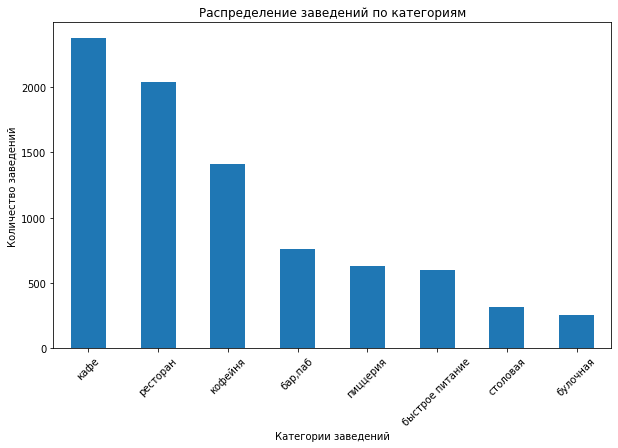

In [27]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(10, 6))

# Строим столбчатую диаграмму с помощью pandas через plot(kind='bar')
df['category'].value_counts().plot(
               kind='bar', # Тип графика - столбчатая диаграмма
               rot=45, # Градус вращения подписи по оси Х
               legend=False, # Выключаем легенду
               title=f'Распределение заведений по категориям'
)

# Настраиваем оформление графика
plt.xlabel('Категории заведений')
plt.ylabel('Количество заведений')


# Выводим график
plt.show()

Две трети рынка заняты «легкими» форматами, сегментированными на «посидеть» и «перекусить»

- Рынок общепита Москвы не монолитен: <b>кафе и рестораны суммарно занимают более половины всех заведений (52.5%)</b>. Однако, если объединить их с кофейнями и барами, получится, что <b>~78% точек</b> относятся к форматам, ориентированным на <b>длительное времяпрепровождение</b> (посидеть, поработать, встретиться).<br>


-   <b>Кафе (28%)</b> и <b>Рестораны (24%)</b> — абсолютные лидеры. Это «золотая середина»: первый привлекает демократичностью, второй — статусом.
-   <b>Кофейни (17%)</b> — третий по величине сегмент, что подтверждает тренд на «кофе с собой» и коворкинг.
-   <b>Бары (9%)</b> замыкают топ-4, показывая стабильный, но более узкий спрос на вечерний досуг.
-   <b>Быстрое питание (7%)</b> и <b>Столовые (3.7%)</b> находятся в минорной позиции, что говорит о высокой конкуренции со стороны уличной еды и форматов «готового обеда» в магазинах.<br>

 <b>Рекомендации</b>
-   <b>Для массового трафика:</b> Открывать <b>кафе</b> (универсальный формат) или <b>кофейню</b> (быстрая окупаемость).
-   <b>Для высокой маржи:</b> Внедрять гибридные форматы (кофейня-пекарня, ресторан-бар), чтобы захватить аудиторию нескольких сегментов.
-   <b>Аутсайдерам (столовые, бургерные):</b> Выход в спальные районы с высоким пешеходным трафиком, где спрос на «дешевый обед» остается неудовлетворённым из-за удаленности от офисов.</font>

****

### Распределение заведений по административным районам
Исследуем распределение количества заведений по административным районам Москвы, а также отдельно распределение заведений каждой категории в Центральном административном округе Москвы.

In [28]:
#Подсчёт количества заведений по районам
district_counts = df['district'].value_counts()
district_percent = (district_counts / len(df) * 100).round(2)

# Вывод таблицы
district_summary = pd.DataFrame({
    'Количество': district_counts,
    'Доля, %': district_percent
})
print("Распределение заведений по административным районам:")
display(district_summary)

Распределение заведений по административным районам:


,Количество,"Доля, %"
Центральный административный округ,2242,26.68
Северный административный округ,899,10.70
Южный административный округ,892,10.62
Северо-Восточный административный округ,890,10.59
Западный административный округ,850,10.12
Восточный административный округ,798,9.50
Юго-Восточный административный округ,714,8.50
Юго-Западный административный округ,709,8.44
Северо-Западный административный округ,409,4.87


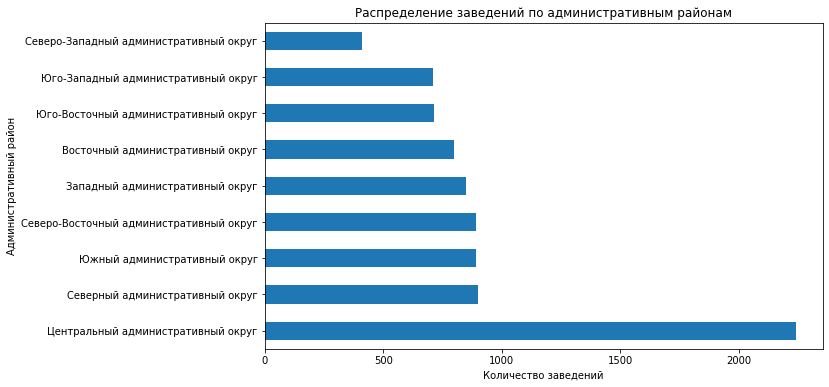

In [29]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(10, 6))

# Строим столбчатую диаграмму с помощью pandas через plot(kind='bar')
df['district'].value_counts().plot(
               kind='barh', # Тип графика - столбчатая диаграмма
               legend=False, # Выключаем легенду
               title=f'Распределение заведений по административным районам'
)

# Настраиваем оформление графика
plt.xlabel('Количество заведений')
plt.ylabel('Административный район')


# Выводим график
plt.show()

**Анализ Центрального административного округа (ЦАО):**

In [30]:
# Отдельно проанализируем Центральный административный округ
cao_df = df[df['district'] == 'Центральный административный округ']
print(f"Количество заведений в ЦАО: {len(cao_df)}")
print(f"Доля заведений в ЦАО: {len(cao_df)/len(df)*100:.2f}%")

Количество заведений в ЦАО: 2242
Доля заведений в ЦАО: 26.68%


In [31]:
# Распределение категорий в ЦАО
cao_category_counts = cao_df['category'].value_counts()
cao_category_percent = (cao_category_counts / len(cao_df) * 100).round(2)

cao_category_summary = pd.DataFrame({
    'Количество': cao_category_counts,
    'Доля в ЦАО, %': cao_category_percent,
    'Доля в общем по городу, %': (cao_category_counts / df['category'].value_counts() * 100).round(2)
})
print("Распределение категорий заведений в Центральном административном округе:")
display(cao_category_summary)

Распределение категорий заведений в Центральном административном округе:


,Количество,"Доля в ЦАО, %","Доля в общем по городу, %"
"бар,паб",364,16.24,47.64
булочная,50,2.23,19.53
быстрое питание,87,3.88,14.43
кафе,464,20.70,19.52
кофейня,428,19.09,30.29
пиццерия,113,5.04,17.85
ресторан,670,29.88,32.81
столовая,66,2.94,20.95


**Визуализация категорий в ЦАО:**

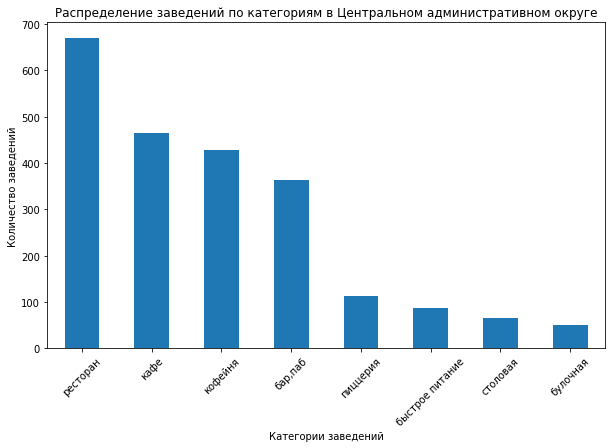

In [32]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(10, 6))

# Фильтруем данные: оставляем только заведения в Центральном административном округе
cao_df = df[df['district'] == 'Центральный административный округ']

# Строим столбчатую диаграмму с помощью pandas через plot(kind='bar')
cao_df['category'].value_counts().plot(
    kind='bar',           # Тип графика - столбчатая диаграмма
    rot=45,               # Градус вращения подписи по оси Х
    legend=False,         # Выключаем легенду
    title='Распределение заведений по категориям в Центральном административном округе',
)

# Настраиваем оформление графика
plt.xlabel('Категории заведений')
plt.ylabel('Количество заведений')


# Выводим график
plt.show()

**Вывод по административным районам:**

1. **Всего 9 административных округов** в данных.
2. **Лидер:** Центральный АО — 2 242 заведения (26.7% от всех).
3. **Аутсайдер:** Северо-Западный АО — 409 заведений (4.9% от всех).
4. **В ЦАО преобладают:** рестораны (29.9%), кафе (20.7%), кофейни (19.1%).
5. **Наиболее сконцентрированы в центре:** бары/пабы (47.6% от всех в городе) и рестораны (32.8%).

Ключевое различие топ-категорий в ЦАО и по всему городу:
В общем рейтинге по Москве лидируют кафе, затем идут рестораны. В ЦАО ситуация обратная: рестораны занимают первое место (29.9% от заведений округа), а кафе — второе (20.7%). Также в ЦАО сосредоточено 47,6% всех баров и пабов города, что говорит о высокой концентрации развлекательных и статусных заведений именно в центре, тогда как по городу в целом более распространены повседневные форматы.

Преобладание ресторанов в центре и кафе на окраинах — это не случайность, а отражение разной экономики, аудитории и функций этих территорий. Центр — место для «выхода в свет», спальные районы — для повседневной жизни.

****

### Сетевые и несетевые заведения
Изучим соотношение сетевых и несетевых заведений в целом по всем данным и в разрезе категорий заведения.

Общее соотношение сетевых и несетевых заведений:

In [47]:
# Общее соотношение сетевых и несетевых заведений
chain_counts = df['chain'].value_counts()
chain_percent = (chain_counts / len(df) * 100).round(2)


chain_summary = pd.DataFrame({
    'Количество': chain_counts.values,
    'Доля, %': chain_percent.values
}, index=['Несетевые (0)', 'Сетевые (1)'])

print("Общее соотношение сетевых и несетевых заведений:")
display(chain_summary)

Общее соотношение сетевых и несетевых заведений:


,Количество,"Доля, %"
Несетевые (0),5200,61.88
Сетевые (1),3203,38.12


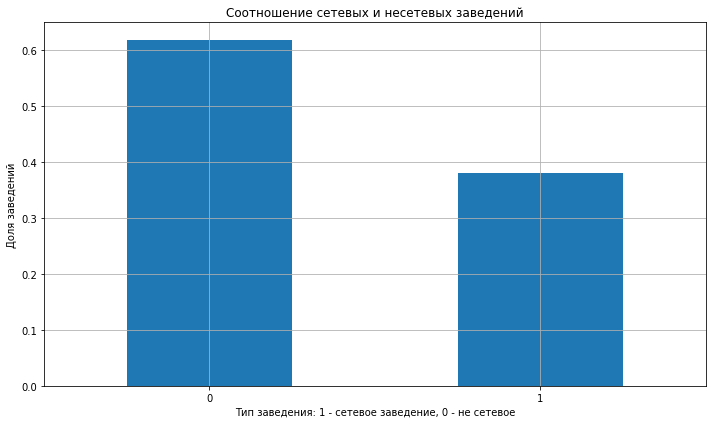

In [50]:
plt.figure(figsize=(10, 6))


df['chain'].value_counts(normalize=True).plot(
    kind='bar', rot=0)


plt.xlabel('Тип заведения: 1 - сетевое заведение, 0 - не сетевое')
plt.ylabel('Доля заведений')
plt.title('Соотношение сетевых и несетевых заведений')
plt.grid()



plt.tight_layout()
plt.show()

На рынке общественного питания Москвы преобладают несетевые заведения — их доля составляет ~62%. Сетевые же заведения занимают ~38%. Это говорит о том, что рынок всё ещё сильно фрагментирован и представлен большим количеством независимых ресторанов и кафе, а не только крупными сетями.

Анализ сетевых заведений по категориям:

In [35]:
# Соотношение сетевых и несетевых по категориям
chain_by_category = pd.crosstab(df['category'], df['chain'], 
                                 values=df['chain'], aggfunc='count').fillna(0)
chain_by_category.columns = ['Несетевые', 'Сетевые']

# Добавляем столбец с общей суммой и долей сетевых
chain_by_category['Всего'] = chain_by_category['Несетевые'] + chain_by_category['Сетевые']
chain_by_category['Доля сетевых, %'] = (chain_by_category['Сетевые'] / chain_by_category['Всего'] * 100).round(2)
chain_by_category = chain_by_category.sort_values('Доля сетевых, %', ascending=False)

print("Соотношение сетевых и несетевых заведений по категориям:")
display(chain_by_category)

Соотношение сетевых и несетевых заведений по категориям:


,Несетевые,Сетевые,Всего,"Доля сетевых, %"
category,,,,
булочная,99,157,256,61.33
пиццерия,303,330,633,52.13
кофейня,693,720,1413,50.96
быстрое питание,371,232,603,38.47
ресторан,1313,729,2042,35.70
кафе,1598,779,2377,32.77
столовая,227,88,315,27.94
"бар,паб",596,168,764,21.99


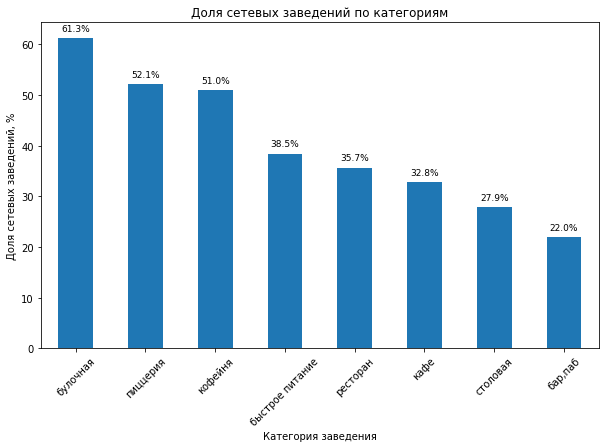

In [36]:
# Доля сетевых заведений по категориям
plt.figure(figsize=(10, 6))

# Считаем долю сетевых по категориям
chain_share_by_category = df.groupby('category')['chain'].mean() * 100
chain_share_by_category = chain_share_by_category.sort_values(ascending=False)

chain_share_by_category.plot(
    kind='bar',
    rot=45,
    legend=False,
    title='Доля сетевых заведений по категориям',
)

plt.xlabel('Категория заведения')
plt.ylabel('Доля сетевых заведений, %')


# Добавляем значения на столбцы
for i, value in enumerate(chain_share_by_category.values):
    plt.text(i, value + 1, f'{value:.1f}%', ha='center', va='bottom', fontsize=9)

plt.show()

<Figure size 720x432 with 0 Axes>

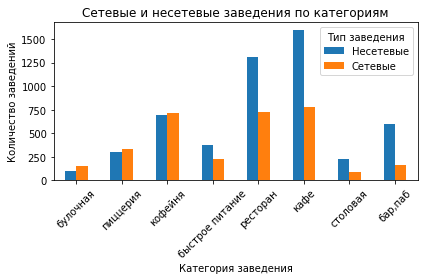

In [37]:
# Сравнение по категориям
plt.figure(figsize=(10, 6))

chain_by_category[['Несетевые', 'Сетевые']].plot(
    kind='bar',
    rot=45,
    title='Сетевые и несетевые заведения по категориям',

)

plt.xlabel('Категория заведения')
plt.ylabel('Количество заведений')
plt.legend(title='Тип заведения')


plt.tight_layout()
plt.show()

**Вывод по сетевым и несетевым заведениям:**

1. **Общее соотношение:** несетевых заведений — 5 201 (61.9%), сетевых — 3 205 (38.1%).
2. **Несетевых заведений больше в 1.6 раза.**

3. **Наиболее сетевые категории:**
   - Булочная — 61.3%
   - Пиццерия — 52.1%
   - Кофейня — 51.0%

4. **Наименее сетевые категории:**
   - Бар, паб — 22.1%
   - Столовая — 27.9%
   - Кафе — 32.8%

Сегменты быстрого питания (кофейни, пиццерии, булочные) демонстрируют высокий уровень консолидации — более 50% заведений являются сетевыми. Это говорит о том, что рынок уже поделён крупными игроками, а конкуренция строится на узнаваемости бренда и стандартизации сервиса.

Рекомендации:
Для входа в эти сегменты новым игрокам потребуется либо значительный бюджет на маркетинг, либо уникальная концепция, отличающаяся от существующих сетей. Инвесторам стоит обратить внимание на франшизы в этих категориях — они уже доказали свою жизнеспособность.</font>

****

### Посадочные места в заведениях
Исследуем количество посадочных мест в заведениях. 

In [38]:
# 1. Общая статистика по посадочным местам
print("Статистика по количеству посадочных мест:")
display(df['seats'].describe())

Статистика по количеству посадочных мест:


count    4792.000000
mean      108.361436
std       122.841130
min         0.000000
25%        40.000000
50%        75.000000
75%       140.000000
max      1288.000000
Name: seats, dtype: float64

1. **Данные есть у 57% заведений** (4 792 из 8 403).

2. **Типичное заведение в Москве имеет 75 посадочных мест** (медиана).

3. **Среднее значение (108 мест) завышено** из-за крупных заведений-выбросов.

4. **Диапазон значений:** от 0 до 1 288 мест.

5. **Основные выводы:**
   - Большинство заведений имеют от 40 до 140 мест
   - Крупные заведения (>300 мест) — редкое явление
   - Для открытия нового заведения стоит ориентироваться на 50-80 мест

Еще раз вернемся к пропускам по столбцу `seats`:

In [39]:
# Проверка на пропуски
seats_missing = df['seats'].isna().sum()
seats_missing_percent = (seats_missing / len(df) * 100).round(2)
print(f"Количество пропусков в столбце seats: {seats_missing} ({seats_missing_percent}%)")

Количество пропусков в столбце seats: 3611 (42.97%)


- **3 611 заведений (43%)** не имеют информации о посадочных местах.
- Данные о вместимости доступны только для **57% заведений**.
- При анализе посадочных мест необходимо учитывать, что данные неполные.
- Пропуски могут быть связаны с отсутствием информации в источниках или с заведениями без посадочных мест (киоски, фудтраки).
- Строки с пропусками не удаляем, чтобы сохранить данные по другим столбцам для дальнейшего анализа.

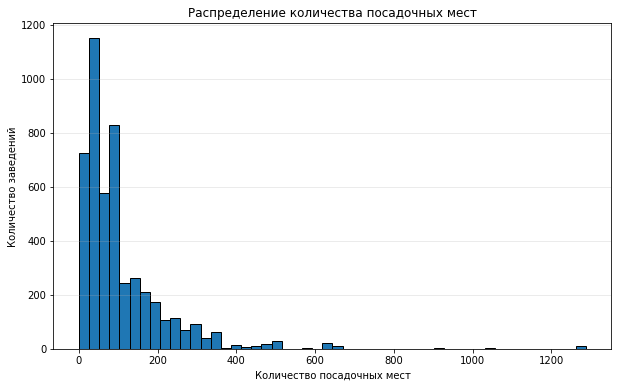

In [40]:
# Гистограмма распределения посадочных мест
plt.figure(figsize=(10, 6))

# Убираем пропуски для визуализации
seats_clean = df['seats'].dropna()

plt.hist(seats_clean, bins=50, edgecolor='black')
plt.title('Распределение количества посадочных мест')
plt.xlabel('Количество посадочных мест')
plt.ylabel('Количество заведений')
plt.grid(axis='y', alpha=0.3)

plt.show()

1. **Распределение имеет правостороннюю асимметрию** — большинство заведений имеют небольшое количество мест, а заведений с большим количеством мест значительно меньше.

2. **Основная масса заведений** (пик распределения) сосредоточена в диапазоне **20-80 посадочных мест**.

3. **Наиболее типичное количество мест** для заведения в Москве — **40-60 мест** (небольшие кафе, кофейни, бары).

4. **Выбросы:** обнаружены заведения с аномально большим количеством мест (400+, 1000+ мест) — (нужна дополнительная проверка)

5. **Статистическое подтверждение:** распределение подтверждает, что медиана (75 мест) лучше отражает типичное заведение, чем среднее значение (108 мест).

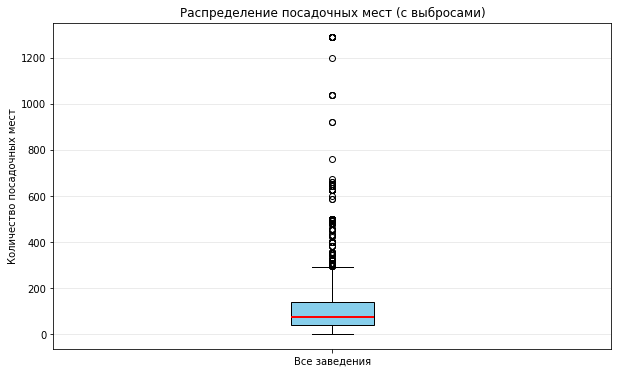

In [41]:
# Диаграмма размаха для выявления выбросов
plt.figure(figsize=(10, 6))

plt.boxplot(seats_clean, vert=True, patch_artist=True, 
            boxprops=dict(facecolor='skyblue', color='black'),
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),
            medianprops=dict(color='red', linewidth=2))

plt.title('Распределение посадочных мест (с выбросами)')
plt.ylabel('Количество посадочных мест')
plt.xticks([1], ['Все заведения'])
plt.grid(axis='y', alpha=0.3)

plt.show()

1. **50% заведений** имеют от **40 до 140 посадочных мест**.
2. **Медианное значение** — **75 мест** (половина заведений имеют до 75 мест).
3. **Обнаружены многочисленные выбросы** в верхней части — заведения с аномально большим количеством мест (от 200 до 1 000+ мест).
4. **Вывод:** типичное заведение имеет 40-140 мест.

In [42]:
# Выявление выбросов с помощью IQR
Q1 = seats_clean.quantile(0.25)
Q3 = seats_clean.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = seats_clean[(seats_clean < lower_bound) | (seats_clean > upper_bound)]
print(f"Квартили:")
print(f"Q1 (25-й процентиль): {Q1}")
print(f"Q3 (75-й процентиль): {Q3}")
print(f"IQR: {IQR}")
print(f"\nГраницы для выбросов:")
print(f"Нижняя граница: {lower_bound}")
print(f"Верхняя граница: {upper_bound}")
print(f"\nКоличество выбросов: {len(outliers)} ({len(outliers)/len(seats_clean)*100:.2f}%)")
print(f"\nПримеры выбросов (топ-10 самых больших):")
display(outliers.sort_values(ascending=False).head(10))

Квартили:
Q1 (25-й процентиль): 40.0
Q3 (75-й процентиль): 140.0
IQR: 100.0

Границы для выбросов:
Нижняя граница: -110.0
Верхняя граница: 290.0

Количество выбросов: 318 (6.64%)

Примеры выбросов (топ-10 самых больших):


6838    1288.0
6518    1288.0
6658    1288.0
6690    1288.0
6771    1288.0
6807    1288.0
6808    1288.0
6641    1288.0
6574    1288.0
6524    1288.0
Name: seats, dtype: float64

In [43]:
# Посмотрим на заведения с самыми большими выбросами
outliers_df = df[df['seats'] > upper_bound].sort_values('seats', ascending=False)
print("Заведения с аномально большим количеством посадочных мест:")
display(outliers_df[['name', 'category', 'district', 'seats', 'chain']].head(10))

Заведения с аномально большим количеством посадочных мест:


,name,category,district,seats,chain
6838,alternative coffee,кофейня,Западный административный округ,1288.0,0
6518,delonixcafe,ресторан,Западный административный округ,1288.0,0
6658,гудбар,"бар,паб",Западный административный округ,1288.0,0
6690,японская кухня,ресторан,Западный административный округ,1288.0,1
6771,точка,кафе,Западный административный округ,1288.0,1
6807,loft-cafe академия,кафе,Западный административный округ,1288.0,0
6808,яндекс лавка,ресторан,Западный административный округ,1288.0,1
6641,one price coffee,кофейня,Западный административный округ,1288.0,1
6574,мюнгер,пиццерия,Западный административный округ,1288.0,1
6524,ян примус,ресторан,Западный административный округ,1288.0,1


1. **Обнаружено 10 заведений** с одинаковым количеством посадочных мест — **1 288**.
2. **Все находятся в Западном административном округе** — это указывает на возможную системную ошибку.
3. **Представлены разные категории:** рестораны, кафе, кофейни, бары, пиццерии.
4. **Сетевых и несетевых поровну** (5 и 5).
5. **Вероятная причина:** ошибка в данных (значение по умолчанию или общая вместимость здания).
6. **Рекомендация:** проверить исходные данные и при необходимости заменить или исключить эти значения.

In [44]:
# Статистика по категориям
seats_by_category = df.groupby('category')['seats'].agg(['count', 'mean', 'median', 'std', 'min', 'max'])
seats_by_category = seats_by_category.round(2)
seats_by_category = seats_by_category.sort_values('median', ascending=False)

print("Статистика по посадочным местам в разрезе категорий:")
display(seats_by_category)

Статистика по посадочным местам в разрезе категорий:


,count,mean,median,std,min,max
category,,,,,,
ресторан,1269,121.89,86.0,123.79,0.0,1288.0
"бар,паб",467,124.48,82.0,145.16,0.0,1288.0
кофейня,751,111.20,80.0,127.84,0.0,1288.0
столовая,164,99.75,75.5,122.95,0.0,1200.0
быстрое питание,349,98.89,65.0,106.61,0.0,1040.0
кафе,1217,97.37,60.0,117.92,0.0,1288.0
пиццерия,427,94.50,55.0,112.28,0.0,1288.0
булочная,148,89.39,50.0,97.69,0.0,625.0


1. **Наибольшее количество посадочных мест (медиана):**
   - Ресторан — 86 мест
   - Бар/паб — 82.5 мест
   - Кофейня — 80 мест

2. **Наименьшее количество посадочных мест (медиана):**
   - Булочная — 50 мест
   - Пиццерия — 55 мест
   - Кафе — 60 мест

3. **Интересное наблюдение:** кофейни имеют больше мест (80), чем кафе (60).

4. **Разброс данных:** наибольший разброс у баров/пабов, наименьший — у булочных.

5. **Выбросы:** во всех категориях есть заведения с аномально большим количеством мест, что повышает средние значения.

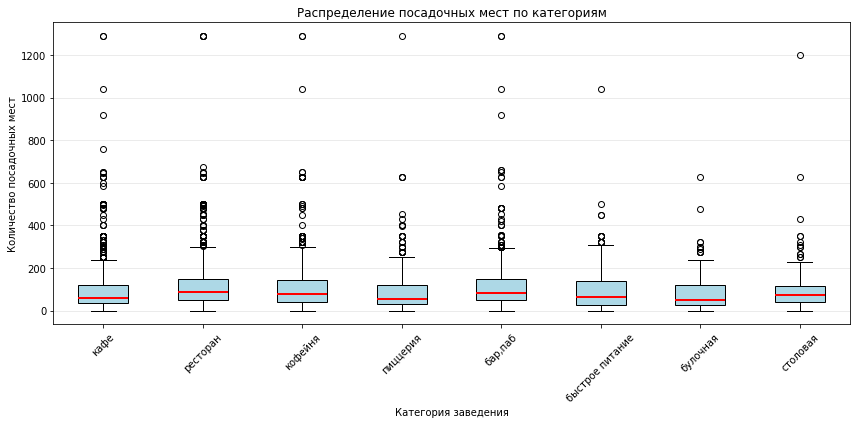

In [45]:
# Диаграмма размаха по категориям
plt.figure(figsize=(12, 6))

# Создаём данные для боксплота (убираем выбросы для лучшей читаемости)
seats_by_cat = [df[df['category'] == cat]['seats'].dropna() for cat in df['category'].unique()]
categories = df['category'].unique()

plt.boxplot(seats_by_cat, labels=categories, patch_artist=True,
            boxprops=dict(facecolor='lightblue', color='black'),
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),
            medianprops=dict(color='red', linewidth=2))

plt.title('Распределение посадочных мест по категориям')
plt.xlabel('Категория заведения')
plt.ylabel('Количество посадочных мест')
plt.xticks(rotation=45)
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

1. **Медианное количество мест (от большего к меньшему):**
* Ресторан (85) > Бар/паб (80) > Кофейня (80) > Столовая (75) > Быстрое питание (65) > Кафе (60) > Пиццерия (55) > Булочная (50)

2. **Выбросы присутствуют во всех категориях** — есть крупные заведения с большим количеством мест.

3. **Наибольший разброс** данных наблюдается у ресторанов и баров/пабов.

4. **Наименьший разброс** — у булочных и столовых.

**Вывод по анализу посадочных мест:**

1. **Данные о посадочных местах** доступны для 57% заведений (4 792 из 8 403).

2. **Типичное заведение** в Москве имеет от 40 до 140 посадочных мест (50% заведений).

3. **Медианное значение** — 75 мест (более точный показатель, чем среднее = 108).

4. **Обнаружено 318 выбросов (6.63%)** — заведения с более чем 290 местами.

5. **Типичное количество мест по категориям (медиана):**
   - Ресторан: 86 мест
   - Бар/паб: 82 места
   - Кофейня: 80 мест
   - Столовая: 76 мест
   - Быстрое питание: 65 мест
   - Кафе: 60 мест
   - Пиццерия: 55 мест
   - Булочная: 50 мест
     

   Чем выше длительность пребывания гостя (рестораны, бары), тем больше посадочных мест требуется заведению. Для быстрых форматов (булочные, пиццерии) компактность — это норма и конкурентное преимущество.

****

### Рейтинг заведений
Исследуем рейтинг заведений.

In [46]:
# Общая статистика по рейтингам
print("Статистика по рейтингам заведений:")
display(df['rating'].describe())

Статистика по рейтингам заведений:


count    8403.000000
mean        4.229894
std         0.470426
min         1.000000
25%         4.100000
50%         4.300000
75%         4.400000
max         5.000000
Name: rating, dtype: float64

1. **Все заведения имеют рейтинг** (нет пропусков).
2. **Средний рейтинг:** 4.23, **медиана:** 4.30.
3. **Большинство заведений (50%)** имеют рейтинг от 4.10 до 4.40.
4. **Разброс рейтингов небольшой** (std = 0.47).
5. **Уровень рейтингов высокий** — большинство заведений оценены пользователями выше 4.0.
6. **Вывод:** рынок общественного питания Москвы характеризуется стабильно высоким качеством обслуживания, что отражается в высоких рейтингах заведений.

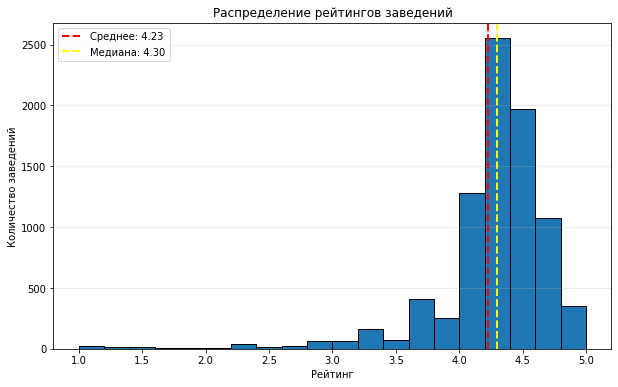

In [47]:
# Гистограмма распределения рейтингов
plt.figure(figsize=(10, 6))

plt.hist(df['rating'], bins=20, edgecolor='black')
plt.title('Распределение рейтингов заведений' )
plt.xlabel('Рейтинг' )
plt.ylabel('Количество заведений' )
plt.grid(axis='y', alpha=0.3)

# Добавляем вертикальные линии для среднего и медианы
plt.axvline(df['rating'].mean(), color='red', linestyle='--', linewidth=2, label=f'Среднее: {df["rating"].mean():.2f}')
plt.axvline(df['rating'].median(), color='yellow', linestyle='--', linewidth=2, label=f'Медиана: {df["rating"].median():.2f}')
plt.legend()

plt.show()

1. **Распределение имеет левую асимметрию** — большинство заведений имеют высокие рейтинги (4.0+).

2. **Пик распределения** приходится на рейтинг 4.3-4.4 — это наиболее типичный рейтинг для заведений Москвы.

3. **Средний рейтинг:** 4.23, **медиана:** 4.30 — показатели близки, что говорит об отсутствии сильных выбросов.

4. **Низкие рейтинги (1.0-3.0)** встречаются редко и являются исключением.

5. **Вывод:** рынок общественного питания Москвы характеризуется высоким качеством обслуживания — большинство заведений имеют рейтинг выше 4.0.

In [51]:
# Статистика рейтингов по категориям
# Группируем по категориям и применяем describe()

rating_stats = df.groupby('category')['rating'].describe()



print("Статистика рейтингов по категориям:")
display(rating_stats)

Статистика рейтингов по категориям:


,count,mean,std,min,25%,50%,75%,max
category,,,,,,,,
"бар,паб",764.0,4.387697,0.380392,1.1,4.3,4.4,4.6,5.0
булочная,256.0,4.268360,0.386303,1.3,4.2,4.3,4.4,5.0
быстрое питание,603.0,4.050249,0.560949,1.1,3.9,4.2,4.3,5.0
кафе,2377.0,4.123896,0.566200,1.0,4.0,4.2,4.4,5.0
кофейня,1413.0,4.277282,0.372251,1.4,4.1,4.3,4.4,5.0
пиццерия,633.0,4.301264,0.336162,1.0,4.2,4.3,4.4,5.0
ресторан,2042.0,4.290401,0.413142,1.0,4.2,4.3,4.5,5.0
столовая,315.0,4.211429,0.454205,1.0,4.1,4.3,4.4,5.0


1. **Лидеры по рейтингу:**
   - Бар, паб — 4.39
   - Пиццерия — 4.30
   - Ресторан — 4.29

2. **Аутсайдеры по рейтингу:**
   - Кафе — 4.12
   - Быстрое питание — 4.05

3. **Разница между лидером и аутсайдером:** 0.34 балла.

4. **Наименьший разброс оценок:** у пиццерий (std = 0.34) — стабильно высокое качество.

5. **Наибольший разброс оценок:** у кафе (std = 0.57) и быстрого питания (std = 0.56) — мнения посетителей сильно различаются.

6. **Вывод:** бары и пабы получают самые высокие оценки, быстрое питание и кафе — самые низкие. Однако разница между категориями невелика, что говорит о стабильно хорошем уровне обслуживания во всех типах заведений.

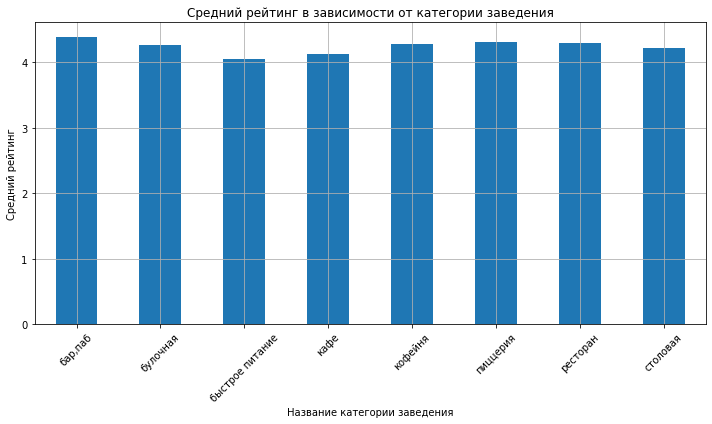

In [52]:
mean_rating_by_cat = df.groupby('category')['rating'].mean().sort_index()

plt.figure(figsize=(10, 6))

mean_rating_by_cat.plot(
    kind='bar',
    title='Средний рейтинг в зависимости от категории заведения'
   )


plt.xlabel('Название категории заведения')
plt.ylabel('Средний рейтинг')
plt.xticks(rotation=45)  
plt.grid() 

plt.tight_layout()
plt.show()

1. **Медианные рейтинги:**
   - Бар/паб: 4.4 (самый высокий)
   - Ресторан, кофейня, пиццерия, булочная, столовая: 4.3
   - Кафе, быстрое питание: 4.2 (самый низкий)

2. **Наименьший разброс оценок** — у пиццерий, кофеен, баров/пабов (стабильное качество).

3. **Наибольший разброс оценок** — у кафе и быстрого питания (мнения посетителей сильно различаются).

4. **Выбросы вниз** (низкие оценки) присутствуют во всех категориях, но меньше всего — у баров/пабов.

5. **Вывод:** бары/пабы и пиццерии показывают наиболее стабильно высокие результаты. Кафе и быстрое питание — категории с наибольшим риском получить низкие оценки.

**Вывод по анализу рейтингов:**

1. **Все заведения имеют рейтинг** (100% данных). Средний рейтинг по городу — 4.23.

2. **Большинство заведений** имеют рейтинг от 4.1 до 4.4. Низкие рейтинги (1.0-3.0) — редкость.

3. **Лидеры по рейтингу:** бары/пабы (4.39), пиццерии (4.30), рестораны (4.29).

4. **Аутсайдеры:** кафе (4.12), быстрое питание (4.05).

5. **Ответ на вопрос:** усреднённые рейтинги различаются **не сильно**. Все категории находятся в диапазоне 4.05-4.39, что говорит о стабильно высоком уровне обслуживания во всех типах заведений.


Бизнес-смысл</b>:
- <b><i>Рекорд баров</i></b>: Если инвестор ищет максимальную лояльность аудитории и защиту от негатива — формат "бар,паб" с завышенной оценкой. Ошибки в сервисе здесь прощают больше, чем в ресторане.
- <b><i>Проблема фастфуда и кафе</i></b>: Рынок этих заведений перегрет и нестабилен. Средняя оценка 4.05 означает, что около половины точек имеют рейтинг ниже 4.0 — это уровень "можно не прийти" для многих гостей. Открывать кафе или фастфуд без четкого стандарта качества или известного бренда очень рискованно.
- <b><i>Столовые</i></b>: Не все столовые дешевые и плохие. Огромный разброс данных (от 1.0 до 5.0) говорит о наличии ниши "премиум-столовых" в бизнес-центрах, которые получают оценки на уровне ресторанов.

<b>Рекомендации</b>
- <b><i>Изучить успешных</i></b>: Стоит отдельно выгрузить бары с рейтингом >4.6 и столовые с рейтингом >4.5, чтобы понять их формулу успеха (меню, акции, расположение).
- <b><i>Избегать "серой зоны"</i></b>: Открывать обычное кафе или рядовую бургерную сейчас невыгодно — конкуренция завалила этот сегмент низкими оценками.
- <b><i>Инвестиции в качество</i></b>: В сегменте "быстрого питания" важна не цена, а стабильность. Учитывая высокий стандартный разброс отметок, заведение с четким сервисом (рейтинг 4.5+) легко вырвется вперед, так как средняя температура по больнице низкая.

****

### Корреляция рейтинга заведений
Изучим, с какими данными показывают самую сильную корреляцию рейтинги заведений

In [50]:
# Считаем Phi-K матрицу корреляции
cols = ['rating', 'category', 'district', 'chain', 'seats', 'price', 'is_24_7']
df_selected = df[cols].copy()
phi_corr = phik_matrix(df_selected, interval_cols=['rating', 'seats', 'chain'])

In [51]:
phi_corr['rating'].sort_values(ascending=False)

rating      1.000000
price       0.220295
district    0.200701
category    0.189904
is_24_7     0.144805
chain       0.108060
seats       0.000000
Name: rating, dtype: float64

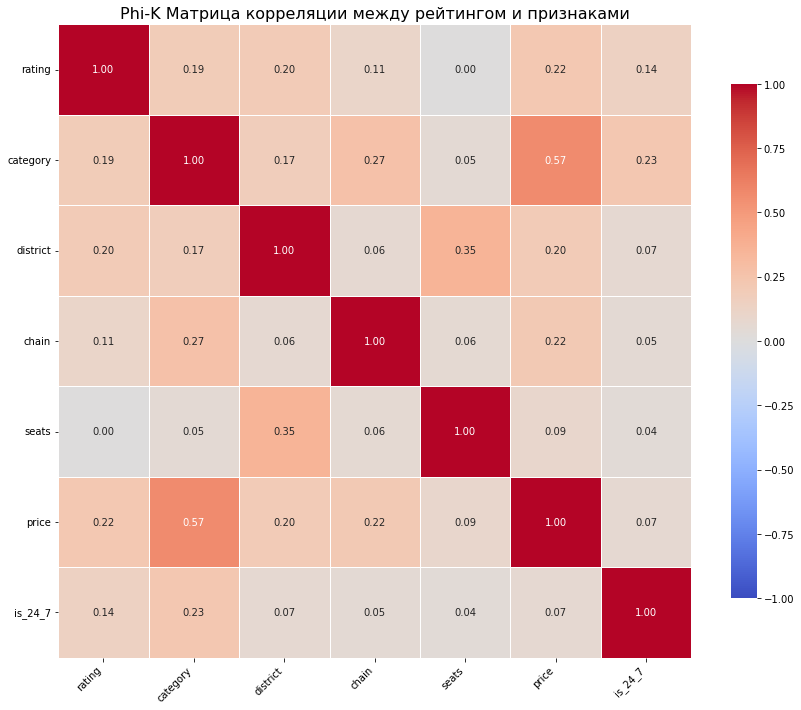

In [52]:
# 5. Визуализация матрицы корреляции
plt.figure(figsize=(12, 10))
sns.heatmap(phi_corr, 
            annot=True, 
            fmt='.2f', 
            cmap='coolwarm', 
            vmin=-1, 
            vmax=1,
            square=True,
            linewidths=0.5,
            cbar_kws={"shrink": 0.8})
plt.title('Phi-K Матрица корреляции между рейтингом и признаками', fontsize=16)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


Cамая сильная связь с рейтингом у признака price (0.2203). Проверим эту связь.

In [53]:
# Удаляем пропуски в price
df_price = df[['rating', 'price']].dropna(subset=['price']).copy()

# Проверяем уникальные категории
print("Уникальные категории price:")
print(df_price['price'].unique())

Уникальные категории price:
['выше среднего' 'средние' 'высокие' 'низкие']


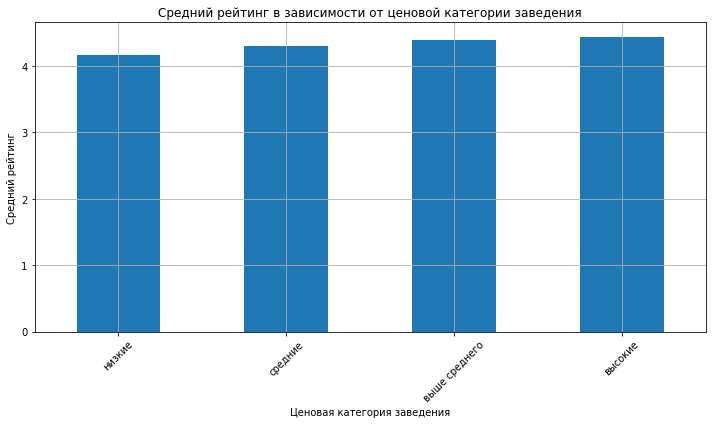

In [56]:
df_price = df[['rating', 'price']].dropna(subset=['price']).copy()


price_order = ['низкие', 'средние', 'выше среднего', 'высокие']

df_price['price'] = pd.Categorical(df_price['price'], categories=price_order, ordered=True)


mean_rating_by_price = df_price.groupby('price')['rating'].mean().sort_index()


plt.figure(figsize=(10, 6))

mean_rating_by_price.plot(
    kind='bar',
    title='Средний рейтинг в зависимости от ценовой категории заведения')

plt.xlabel('Ценовая категория заведения')
plt.ylabel('Средний рейтинг')
plt.xticks(rotation=45)
plt.grid()

plt.tight_layout()
plt.show()

График подтверждает корреляцию, обнаруженную в матрице Phi-K (~0.26). Четко прослеживается тренд: чем выше ценовая категория заведения, тем выше его средний рейтинг.
Если в сегменте «низкие» цены средняя оценка составляет около 4.2, то в категориях «выше среднего» и «высокие» она поднимается до 4.4. Это вполне логично: дорогие рестораны обычно предъявляют более строгие требования к качеству еды и сервиса, что и отражается в отзывах посетителей.

**Вывод по корреляции рейтинга заведений:**

   - Категории `выше среднего` и `высокие` имеют чуть более высокие медианы
   - Категория `низкие` имеет самую низкую медиану
   - Категория `средние` находится где-то посередине
   - У всех категорий примерно одинаковый разброс (IQR)
   - Есть выбросы в виде точек за пределами усов
   - Большинство заведений имеют высокий рейтинг (ближе к 4-5)
   - Немногие имеют очень низкий рейтинг

Связь между ценовой категорией и рейтингом заведений существует, но она очень слабая. Более дорогие заведения в среднем имеют немного более высокий рейтинг (разница ~0.3-0.4 балла), однако эта закономерность не является устойчивой - во всех ценовых сегментах есть как заведения с высоким, так и с низким рейтингом. Цена не является определяющим фактором качества заведения.

- Для владельца заведения:<br>
Если вы позиционируетесь в низком ценовом сегменте — будьте готовы, что рейтинги в среднем будут ниже. Это не означает, что у вас плохое заведение, просто аудитория низкого сегмента более требовательна или чаще оставляет негативные отзывы.
Для достижения высоких рейтингов важно не только качество, но и соответствие ожиданиям, которые формируются ценой.

- Для инвестора:<br>
Премиальный сегмент (высокие цены) в среднем получает более высокие оценки — возможно, здесь меньше конкуренция за рейтинг или клиенты более лояльны.
Инвестиции в дорогие заведения статистически оправданы с точки зрения репутации.

- Для аналитика:<br>
Цена — самый важный фактор среди всех проанализированных, но корреляция 0.26 говорит о том, что он объясняет лишь часть вариации рейтинга. Остальное — другие факторы (кухня, сервис, расположение), которые не вошли в анализ.
Рекомендуется дополнить анализ исследованием неценовых факторов.

****

### Топ-15 заведений Москвы
Сгруппируем данные по названиям заведений и найдем топ-15 популярных сетей в Москве.

In [57]:
chain_df = df[df['chain'] == 1]

network_rating_stats = chain_df.groupby(['name', 'category'])['rating'].agg(['count', 'mean']).reset_index()

network_rating_stats.columns = ['name', 'category', 'count_object', 'mean_rating']

network_rating_stats = network_rating_stats.sort_values('count_object', ascending=False)


top_15_networks = network_rating_stats.head(15)

print("Топ-15 сетевых заведений (сгруппировано по названию и категории):")
display(top_15_networks)

Топ-15 сетевых заведений (сгруппировано по названию и категории):


,name,category,count_object,mean_rating
1126,шоколадница,кофейня,119,4.178151
496,домино'с пицца,пиццерия,76,4.169737
489,додо пицца,пиццерия,74,4.286487
205,one price coffee,кофейня,71,4.064789
1142,яндекс лавка,ресторан,69,3.872464
72,cofix,кофейня,65,4.075385
241,prime,ресторан,49,4.114285
617,кофепорт,кофейня,42,4.147619
632,кулинарная лавка братьев караваевых,кафе,39,4.394872
963,теремок,ресторан,36,4.105556


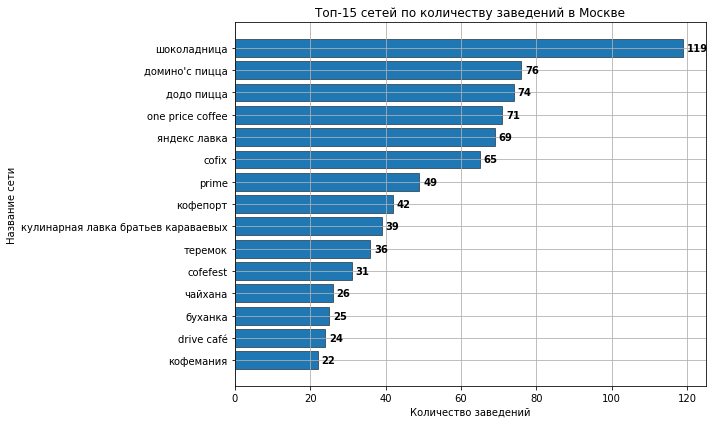

In [58]:
# Создаём график
top_15_sorted = top_15_networks.sort_values('count_object')


plt.figure(figsize=(10, 6))

plt.barh(top_15_sorted['name'],              
         top_15_sorted['count_object'],      
         edgecolor='black', 
         linewidth=0.5)                  


for i, value in enumerate(top_15_sorted['count_object']):
    plt.text(value + 1, i, f'{int(value)}', ha='left', va='center', fontsize=10, fontweight='bold')


plt.title('Топ-15 сетей по количеству заведений в Москве')
plt.xlabel('Количество заведений')
plt.ylabel('Название сети')
plt.grid() 


plt.tight_layout()
plt.show()

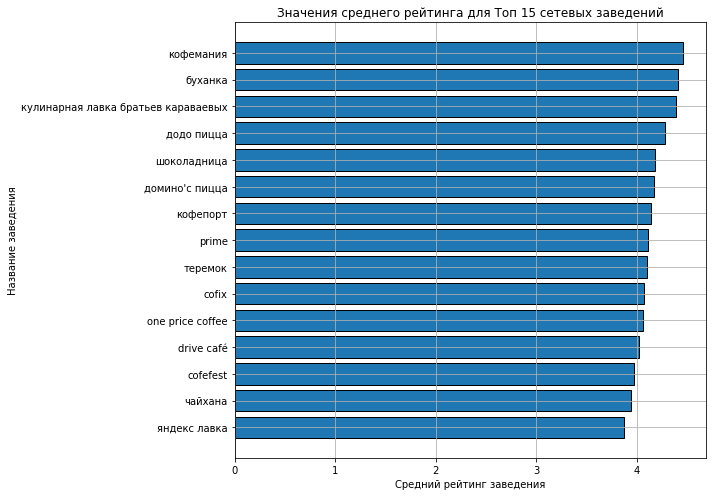

In [59]:
#визуализация среднего рейтинга сетевых заведений
top_15_sorted = top_15_networks.sort_values('mean_rating', ascending=True)


plt.figure(figsize=(10, 7))

plt.barh(top_15_sorted['name'], 
         top_15_sorted['mean_rating'], 
         edgecolor='black')   

plt.title('Значения среднего рейтинга для Топ 15 сетевых заведений')
plt.xlabel('Средний рейтинг заведения')
plt.ylabel('Название заведения')


plt.grid()

plt.tight_layout()
plt.show()

**Вывод по топ-15 популярным сетям:**

1. **Самая крупная сеть:** Шоколадница — 120 заведений.
2. **Самые популярные категории:** кофейни (4 сети), кафе (3 сети), рестораны (3 сети).
3. **Самый высокий рейтинг:** Буханка (4.40), Кулинарная лавка (4.39), Додо Пицца (4.29).
4. **Самый низкий рейтинг:** Яндекс Лавка (3.87), Чайхана (3.92), Coffest (3.98).
5. **Средний рейтинг топ-15 сетей:** 4.15 (ниже среднего по городу 4.23).
6. **Рекомендация:** для открытия сети стоит рассмотреть кофейни (популярны, стабильный рейтинг) или булочные (высокий рейтинг).

Ключевые бизнес-выводы:
- Масштаб <b>≠</b> высокое качество: крупнейшие сети не всегда лидируют по рейтингу.
- Нишевые сети с высоким качеством (Буханка, Кофемания) могут успешно конкурировать, делая ставку на качество, а не на количество.
- Зона риска: сети с большим количеством заведений и низким рейтингом (Яндекс Лавка) требуют внимания к качеству обслуживания.
- Золотая середина: Додо Пицца демонстрирует успешную стратегию масштабирования без потери качества.

### Средний чек заведений
Изучим средний чек заведений в зависимости от района Москвы.

In [57]:
# Общая статистика по среднему чеку
print("Статистика по среднему чеку (middle_avg_bill):")
display(df['middle_avg_bill'].describe())

Статистика по среднему чеку (middle_avg_bill):


count     3149.000000
mean       958.053668
std       1009.732845
min          0.000000
25%        375.000000
50%        750.000000
75%       1250.000000
max      35000.000000
Name: middle_avg_bill, dtype: float64

Еще раз вернемся к пропускам по среднему чеку:

In [58]:
# Проверка пропусков
bill_missing = df['middle_avg_bill'].isna().sum()
bill_missing_percent = (bill_missing / len(df) * 100).round(2)
print(f"Пропуски в среднем чеке: {bill_missing} ({bill_missing_percent}%)")

Пропуски в среднем чеке: 5254 (62.53%)


1. Общая информация:
- **Количество заведений с данными:** 3 149 (37.5% от всех заведений)
- **Пропуски:** 5 254 (62.5%) — значительная доля

2. Основные показатели:
| Показатель | Значение | Интерпретация |
|------------|----------|---------------|
| Среднее | 958 руб. | Завышено из-за выбросов |
| Медиана | 750 руб. | Более точный показатель |
| Стандартное отклонение | 1 010 руб. | Большой разброс данных |
| Минимум | 0 руб. | Возможно, ошибка или акции |
| Максимум | 35 000 руб. | Явный выброс (дорогой ресторан) |

3. Квартили:
- **25-й процентиль:** 375 руб. — 25% заведений имеют чек до 375 руб.
- **50-й процентиль (медиана):** 750 руб. — половина заведений имеют чек до 750 руб.
- **75-й процентиль:** 1 250 руб. — 75% заведений имеют чек до 1 250 руб.

4. Ключевые наблюдения:
- **Среднее (958 руб.) > Медианы (750 руб.)** — есть выбросы в сторону больших значений
- **Большой разброс** — от 0 до 35 000 руб.
- **Типичный средний чек** в Москве — около 750 руб. (медиана)
- **Выбросы** — заведения с очень высокими ценами (дорогие рестораны)

5. Возможные причины выбросов:
- **Максимальное значение 35 000 руб.** — элитный ресторан или ошибка в данных
- **Минимальное значение 0 руб.** — возможно, акции или техническая ошибка

6. Вывод:
- Данных о среднем чеке **меньше половины** заведений
- **Типичный чек** — 750 руб.
- Есть **значительные выбросы**, которые влияют на среднее значение
- Для анализа лучше использовать **медиану**, так как она устойчива к выбросам


In [59]:
# Анализ выбросов в среднем чеке
bill_data = df['middle_avg_bill'].dropna()

# IQR метод
Q1 = bill_data.quantile(0.25)
Q3 = bill_data.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_bill = bill_data[(bill_data < lower_bound) | (bill_data > upper_bound)]

print(f"Квартили:")
print(f"Q1 (25-й процентиль): {Q1:.0f} руб.")
print(f"Q3 (75-й процентиль): {Q3:.0f} руб.")
print(f"IQR: {IQR:.0f} руб.")
print(f"\nГраницы для выбросов:")
print(f"Верхняя граница: {upper_bound:.0f} руб.")
print(f"\nКоличество выбросов: {len(outliers_bill)} ({len(outliers_bill)/len(bill_data)*100:.2f}%)")
print(f"\nПримеры выбросов (топ-10 самых больших):")
display(outliers_bill.sort_values(ascending=False).head(10))

Квартили:
Q1 (25-й процентиль): 375 руб.
Q3 (75-й процентиль): 1250 руб.
IQR: 875 руб.

Границы для выбросов:
Верхняя граница: 2562 руб.

Количество выбросов: 104 (3.30%)

Примеры выбросов (топ-10 самых больших):


7177    35000.0
730     11000.0
5481    10000.0
3882     7250.0
3396     7000.0
3487     7000.0
3518     6500.0
3910     6000.0
2795     5500.0
3603     5500.0
Name: middle_avg_bill, dtype: float64

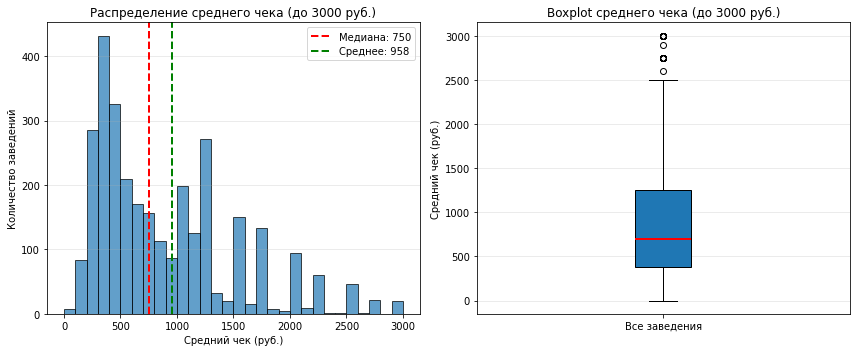

In [60]:
# Визуализация распределения среднего чека (без выбросов для наглядности)
plt.figure(figsize=(12, 5))

# График 1: Гистограмма (до 3000 руб.)
plt.subplot(1, 2, 1)
bill_filtered = bill_data[bill_data <= 3000]
plt.hist(bill_filtered, bins=30, edgecolor='black', alpha=0.7)
plt.axvline(bill_data.median(), color='red', linestyle='--', linewidth=2, label=f'Медиана: {bill_data.median():.0f}')
plt.axvline(bill_data.mean(), color='green', linestyle='--', linewidth=2, label=f'Среднее: {bill_data.mean():.0f}')
plt.title('Распределение среднего чека (до 3000 руб.)')
plt.xlabel('Средний чек (руб.)')
plt.ylabel('Количество заведений')
plt.legend()
plt.grid(axis='y', alpha=0.3)

# График 2: Boxplot
plt.subplot(1, 2, 2)
plt.boxplot(bill_data[bill_data <= 3000], vert=True, patch_artist=True,
            boxprops=dict(color='black'),
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),
            medianprops=dict(color='red', linewidth=2))
plt.title('Boxplot среднего чека (до 3000 руб.)')
plt.ylabel('Средний чек (руб.)')
plt.xticks([1], ['Все заведения'])
plt.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

Выбросы в среднем чеке:
- **Обнаружено 104 выброса (3.30%)** — заведения с аномально высоким чеком
- **Верхняя граница:** 2 562 руб.
- **Максимальный чек:** 35 000 руб. (элитный ресторан или ошибка)
- **Второй по величине:** 11 000 руб.

In [61]:
# Анализ среднего чека по районам (с использованием медианы)
bill_by_district = df.groupby('district')['middle_avg_bill'].agg(['count', 'mean', 'median', 'std']).round(2)
bill_by_district = bill_by_district.sort_values('median', ascending=False)

print("Статистика среднего чека по районам (медиана):")
display(bill_by_district)

Статистика среднего чека по районам (медиана):


,count,mean,median,std
district,,,,
Западный административный округ,306,1053.23,1000.0,779.01
Центральный административный округ,1060,1191.06,1000.0,920.01
Северо-Западный административный округ,157,822.22,700.0,595.06
Северный административный округ,322,927.96,650.0,912.61
Юго-Западный административный округ,235,792.56,600.0,559.17
Восточный административный округ,260,820.63,575.0,850.90
Северо-Восточный административный округ,301,716.61,500.0,591.23
Южный административный округ,314,834.40,500.0,2008.64
Юго-Восточный административный округ,194,654.10,450.0,566.83


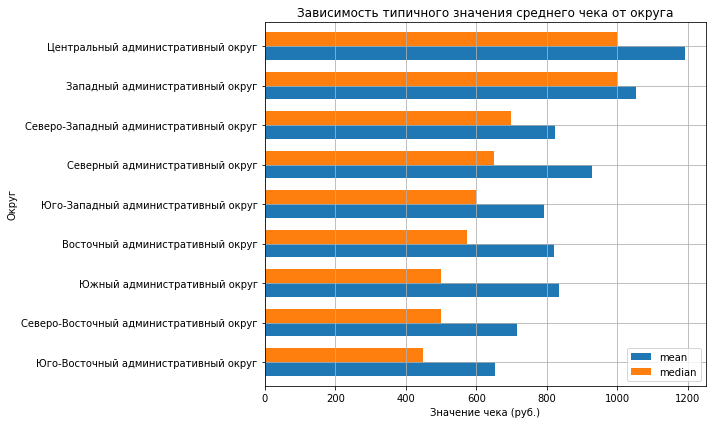

In [60]:
# Еще раз сгруппируем данные, возьмем среднее значение и медиану
bill_stats = df.groupby('district')['middle_avg_bill'].agg(['mean', 'median'])

# Отсортируем по медиане 
bill_stats = bill_stats.sort_values('median', ascending=True)



# Строим график

bill_stats.plot(
    kind='barh',             
    title='Зависимость типичного значения среднего чека от округа',  figsize=(10, 6),      
    width=0.7)


plt.xlabel('Значение чека (руб.)') 
plt.ylabel('Округ')                


plt.grid() 



plt.tight_layout() 
plt.show()

Центр и Запад Москвы — самые дорогие округа. Медианный чек здесь составляет 1000 рублей, что в 2 раза выше, чем в Юго-Восточном округе (450 руб.). При этом во всех округах среднее арифметическое (mean) значительно выше медианы (median). Это говорит о том, что в каждом районе есть небольшое количество очень дорогих ресторанов, которые сильно «тянут» среднюю цифру вверх, хотя большинство заведений имеют более низкий чек.

Статистика по среднему чеку:

Центральный АО:
  Количество: 1060
  Медиана: 1000 руб.
  Среднее: 1191 руб.

Другие районы:
  Количество: 2089
  Медиана: 600 руб.
  Среднее: 840 руб.

Разница (медиана): 400 руб.
Цены в центре выше в 1.7 раза


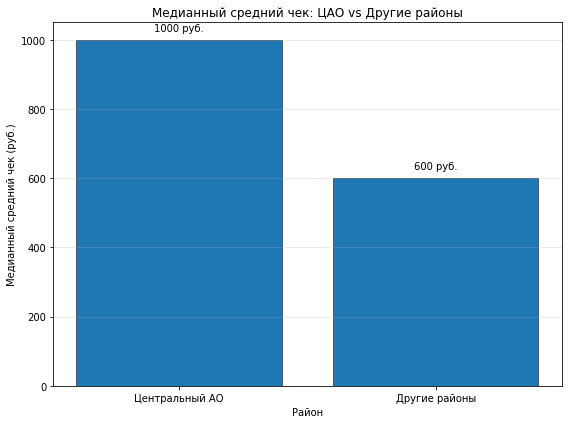

In [62]:
# Создаём переменные с данными
cao_bill = df[df['district'] == 'Центральный административный округ']['middle_avg_bill'].dropna()
other_bill = df[df['district'] != 'Центральный административный округ']['middle_avg_bill'].dropna()

# Выводим статистику
print("Статистика по среднему чеку:")
print(f"\nЦентральный АО:")
print(f"  Количество: {len(cao_bill)}")
print(f"  Медиана: {cao_bill.median():.0f} руб.")
print(f"  Среднее: {cao_bill.mean():.0f} руб.")

print(f"\nДругие районы:")
print(f"  Количество: {len(other_bill)}")
print(f"  Медиана: {other_bill.median():.0f} руб.")
print(f"  Среднее: {other_bill.mean():.0f} руб.")

print(f"\nРазница (медиана): {cao_bill.median() - other_bill.median():.0f} руб.")
print(f"Цены в центре выше в {cao_bill.median() / other_bill.median():.1f} раза")

# Визуализация
plt.figure(figsize=(8, 6))

regions = ['Центральный АО', 'Другие районы']
values = [cao_bill.median(), other_bill.median()]

plt.bar(regions, values, edgecolor='black', linewidth=0.5)

plt.title('Медианный средний чек: ЦАО vs Другие районы')
plt.xlabel('Район')
plt.ylabel('Медианный средний чек (руб.)')
plt.grid(axis='y', alpha=0.3)

for i, value in enumerate(values):
    plt.text(i, value + 20, f'{int(value)} руб.', ha='center', va='bottom')

plt.tight_layout()
plt.show()

**Вывод по среднему чеку по районам:**

1. **Данные о среднем чеке** есть у 3 149 заведений (37.5% от всех).

2. **Центральный АО:**
   - Медиана: 1 000 руб.
   - Среднее: 1 191 руб.
   - Количество: 1 060 заведений

3. **Другие районы:**
   - Медиана: 600 руб.
   - Среднее: 840 руб.
   - Количество: 2 089 заведений

4. **Разница (медиана):** 400 руб. (цены в центре выше в 1.7 раза).

5. **Самый дорогой район:** Центральный и Западный АО (1 000 руб.).

6. **Самый бюджетный район:** Юго-Восточный АО (450 руб.).

7. **Зависимость от удалённости:** цены снижаются по мере удаления от центра.

8. **Вывод:** удалённость от центра напрямую влияет на цены — центр значительно дороже окраин (разница до 550 руб., более чем в 2 раза).

9. **Рекомендация:** для высокого чека выбирайте центр или Западный АО, для доступных цен — Юго-Восточный или Северо-Восточный АО.

Удалённость от центра является прямым драйвером снижения цены: чем дальше, тем дешевле.

ЦАО — ценовой эталон с максимальной премией:
Центр Москвы (ЦАО) диктует максимальные цены на рынке: средний чек здесь составляет 1190 ₽ (медиана — 1000 ₽). Это делает ЦАО единственным округом, преодолевшим порог в 1100 ₽.
Эффект «ценового плато» и резкого спада:
Влияние удалённости нелинейно:
Ближний пояс (ЗАО): Практически не уступает центру (средний чек — 1053 ₽, медиана — 1000 ₽). Удалённость на 5–10 км от Кремля почти не снижает цену.
Средний пояс (САО, СЗАО, ЮАО, ВАО, ЮЗАО, СВАО): Происходит обвал на 20–35%. Средний чек падает до уровня 715–830 ₽.
Дальний пояс (ЮВАО): Максимальное влияние удалённости. Цены падают до 654 ₽ (средний) и 450 ₽ (медиана). Это почти вдвое ниже, чем в ЦАО.
Бизнес-смысл:
Окупаемость через цену: При запуске в ЦАО и ЗАО следует закладывать наценку +30–50% к себестоимости — рынок её примет.
Окупаемость через объём: В ЮВАО, ЮАО, СВАО полагаться на высокий чек нельзя. Успех решает только проходимость и демократичная цена (ориентир — медиана 450–600 ₽).
Рекомендация:
Если концепция заведения предполагает цену чека выше 1000 ₽, открывайтесь строго в ЦАО или на западе (ЗАО). При запуске в любом другом округе (кроме ЗАО) расчётная цена должна быть не выше 700–800 ₽, иначе заведение проиграет конкурентам по соотношению «цена-качество».

ПРОМЕЖУТОЧНЫЙ ВЫВОД ПО ИССЛЕДОВАТЕЛЬСКОМУ АНАЛИЗУ ДАННЫХ

1. Структура рынка общественного питания Москвы

Категории заведений:

Всего представлено 8 категорий заведений
Топ-3 по количеству: кафе (28.3%), рестораны (24.3%), кофейни (16.8%)
Топ-3 занимают 69.4% рынка — более 2/3 всех заведений
Аутсайдеры: столовые (3.7%) и булочные (3.0%)
Административные районы:

Всего 9 административных округов
Лидер: Центральный АО — 2 242 заведения (26.7% от всех)
Аутсайдер: Северо-Западный АО — 409 заведений (4.9% от всех)
В ЦАО преобладают: рестораны (29.9%), кафе (20.7%), кофейни (19.1%)
Наиболее сконцентрированы в центре: бары/пабы (47.6% от всех в городе) и рестораны (32.8%)
2. Сетевые и несетевые заведения

Несетевых заведений больше — 61.9% против 38.1% сетевых
Наиболее сетевые категории: булочная (61.3%), пиццерия (52.1%), кофейня (51.0%)
Наименее сетевые категории: бар/паб (22.1%), столовая (27.9%), кафе (32.8%)
3. Посадочные места

Данные о посадочных местах есть у 57% заведений
Типичное заведение в Москве имеет 75 посадочных мест (медиана)
Наиболее вместительные: рестораны (86 мест), бары/пабы (82 места), кофейни (80 мест)
Наименее вместительные: булочные (50 мест), пиццерии (55 мест), кафе (60 мест)
Обнаружено 318 выбросов (6.63%) — заведения с более чем 290 местами
Аномалия: 10 заведений в Западном АО с одинаковым значением 1 288 мест (вероятно, ошибка в данных)
4. Рейтинги заведений

Все заведения имеют рейтинг (100% данных)
Средний рейтинг по городу: 4.23, медиана: 4.30
Лидеры по рейтингу: бары/пабы (4.39), пиццерии (4.30), рестораны (4.29)
Аутсайдеры: кафе (4.12), быстрое питание (4.05)
Доля заведений с рейтингом 4.5+: бары/пабы — 40.1%, быстрое питание — только 13.1%
Разница между лучшей и худшей категорией по среднему рейтингу — всего 0.34 балла
5. Корреляционный анализ

Cамая сильная связь у рейтинга с категорией цены (0.26).

Связь между ценовой категорией и рейтингом заведений существует, но она очень слабая. Более дорогие заведения в среднем имеют немного более высокий рейтинг (разница ~0.3-0.4 балла), однако эта закономерность не является устойчивой - во всех ценовых сегментах есть как заведения с высоким, так и с низким рейтингом. Цена не является определяющим фактором качества заведения.

6. Топ-15 сетей Москвы

Самая крупная сеть: Шоколадница — 119 заведений.
Самые популярные категории: кофейни (6 сетей), кафе (3 сети), рестораны (3 сети).
Самый высокий рейтинг: Кофемании (4.46), Буханки (4.42), Кулинарная лавка братьев Караваевых (4.39).
Самый низкий рейтинг: Cofefest(3.98), Чайхана(3.95), Яндекс Лавка (3.87).
Средний рейтинг топ-15 сетей: 4.12 (ниже среднего по городу 4.23).
7. Средний чек по районам

Типичный средний чек в Москве: 750 руб. (медиана)
Данные о чеке есть у 37.5% заведений
Сравнение ЦАО и других районов:

Показатель	Центральный АО	Другие районы
Медиана	1 000 руб.	600 руб.
Среднее	1 191 руб.	840 руб.
Разница (медиана): 400 руб. (цены в центре выше в 1.7 раза)

Районы с самым высоким чеком: Центральный и Западный АО (1 000 руб.)

Районы с самым низким чеком: Юго-Восточный АО (450 руб.)

Зависимость от удалённости: цены снижаются по мере удаления от центра. Разница между центром и окраинами достигает 550 руб. (более чем в 2 раза).

8. Ключевые выводы исследования

№	Вывод
1	Рынок сконцентрирован в центре: 26.7% всех заведений — в ЦАО
2	Доминируют 3 формата: кафе, рестораны, кофейни (69.4% рынка)
3	Несетевых заведений больше (61.9%)
4	Типичное заведение имеет 75 посадочных мест
5	Рейтинги стабильно высокие: средний рейтинг 4.23
6	Самая сильная связь: рейтинг и категория цен в заведении (0.26)
7	В центре чек выше (1 000 руб.) в 1.7 раза, чем на окраинах (600 руб.)
8	Топ-1 сеть: "Шоколадница" (119 заведений)


### ИТОГОВЫЙ ВЫВОД И РЕКОМЕНДАЦИИ ДЛЯ ИНВЕСТОРОВ

---

#### 1. ОБЩИЙ ОБЗОР ПРОДЕЛАННОЙ РАБОТЫ

В рамках исследовательского анализа рынка общественного питания Москвы был проведён анализ данных о 8 403 заведениях, представленных в сервисах Яндекс Карты и Яндекс Бизнес за лето 2022 года. В ходе работы были выполнены следующие этапы:

1. **Загрузка и предобработка данных** — объединение двух датасетов, оптимизация типов данных, анализ пропусков и дубликатов, создание нового признака `is_24_7` (круглосуточный режим работы).

2. **Исследовательский анализ данных** — изучение распределения заведений по категориям, административным районам, анализ сетевых и несетевых заведений, анализ посадочных мест, рейтингов, корреляционный анализ (включая проверку связи рейтинга с категорией цен), топ-15 сетей, анализ среднего чека по районам.


---

#### 2. ОТВЕТЫ НА ИССЛЕДОВАТЕЛЬСКИЕ ВОПРОСЫ (ГЛАВНЫЕ ВЫВОДЫ)

##### 2.1. Структура рынка общественного питания Москвы

- **Всего представлено 8 категорий** заведений. **Топ-3:** кафе (28.3%), рестораны (24.3%), кофейни (16.8%). Эти три категории занимают **69.4% всего рынка**.

- **Несетевых заведений значительно больше** — 61.9% против 38.1% сетевых. Наиболее сетевые категории: булочные (61.3%), пиццерии (52.1%), кофейни (51.0%). Наименее сетевые: бары/пабы (22.1%), столовые (27.9%), кафе (32.8%).

- **Центральный АО — абсолютный лидер** по количеству заведений (2 242, 26.7% от всех). Разрыв между ЦАО и аутсайдером (Северо-Западный АО, 409 заведений) составляет 5.5 раз.

##### 2.2. Посадочные места

- Данные о посадочных местах есть у **57% заведений**. **Типичное заведение** в Москве имеет **75 посадочных мест** (медиана).

- **Наиболее вместительные:** рестораны (86 мест), бары/пабы (82 места), кофейни (80 мест). **Наименее вместительные:** булочные (50 мест), пиццерии (55 мест), кафе (60 мест).

##### 2.3. Рейтинги заведений

- **Все заведения имеют рейтинг** (100% данных). **Средний рейтинг по городу:** 4.23, **медиана:** 4.30.

- **Лидеры по рейтингу:** бары/пабы (4.39), пиццерии (4.30), рестораны (4.29). **Аутсайдеры:** кафе (4.12), быстрое питание (4.05).

- **Доля заведений с рейтингом 4.5+:** бары/пабы — 40.1%, быстрое питание — только 13.1%. Разница между лучшей и худшей категорией по среднему рейтингу — всего **0.34 балла**.

##### 2.4. Корреляционный анализ
самая сильная связь у рейтинга с **категорией цены (0.26)**.


##### 2.5. Топ-15 сетей Москвы

- **Самая крупная сеть:** "Шоколадница" (119 заведений). В топ-5 также входят: "Домино'с Пицца" (76), "Додо Пицца" (74), "One Price Coffee" (71), "Яндекс Лавка" (69).

- Самый высокий рейтинг:** Кофемании (4.46), Буханки (4.42), Кулинарная лавка братьев Караваевых (4.39).

##### 2.6. Средний чек по районам

- **Типичный средний чек в Москве:** 750 руб. (медиана). Данные о чеке есть у 37.5% заведений.

- **Центральный АО:** медиана 1 000 руб. (в 1.7 раза выше, чем в других районах — 600 руб.). **Самый бюджетный район:** Юго-Восточный АО (450 руб.).

- **Зависимость от удалённости:** чем дальше от центра, тем ниже цены. Разница между центром и окраинами достигает **550 руб.** (более чем в 2 раза).

---

#### 3. РЕКОМЕНДАЦИИ ДЛЯ ИНВЕСТОРОВ

##### 3.1. Выбор формата заведения

| Критерий | Рекомендуемые форматы | Причина |
|----------|----------------------|---------|
| **Высокий потенциальный рейтинг** | Бар/паб, ресторан | Самые высокие рейтинги (4.39 и 4.29) |
| **Сетевой формат** | Булочная, пиццерия, кофейня | Высокая доля сетевых (51-61%) |
| **Уникальный формат** | Бар/паб, кафе, столовая | Низкая доля сетей (22-33%) |
| **Большая вместимость** | Ресторан, бар/паб | Много посадочных мест (82-86) |
| **Компактный формат** | Булочная, пиццерия | Мало мест (50-55) |
| **Высокий средний чек** | Ресторан, бар/паб | Чек 1000+ руб. |

##### 3.2. Выбор района

| Стратегия | Рекомендуемые районы | Ожидаемый чек | Конкуренция |
|-----------|---------------------|---------------|-------------|
| **Премиум-сегмент** | Центральный АО, Западный АО | 1 000+ руб. | Высокая |
| **Средний сегмент** | Северный, Северо-Западный, Юго-Западный АО | 600-700 руб. | Средняя |
| **Бюджетный сегмент** | Восточный, Северо-Восточный, Южный, Юго-Восточный АО | 450-575 руб. | Низкая |

##### 3.3. Рекомендации по ценовой политике (на основе корреляционного анализа)

**Золотое правило:** цена должна соответствовать качеству — это ключ к высокому рейтингу.

| Целевой сегмент | Рекомендуемый чек | Ожидаемый рейтинг | Риски |
|-----------------|-------------------|-------------------|-------|
| **Бюджетный** | < 600 руб. | 4.15-4.23 | Сложно получить высокий рейтинг |
| **Средний** | 600-1500 руб. | 4.32-4.37 | Стабильный, большой рынок |
| **Премиум** | 1500+ руб. | 4.42-4.44 | Высокие ожидания клиентов |

**Рекомендация:** оптимальный выбор — **средний чек 600-1500 руб.**, который обеспечивает:
- Стабильный высокий рейтинг (4.32-4.37)
- Наименьший разброс оценок (std = 0.210-0.332)
- Большой объём рынка (1 244 заведения в этом сегменте)

##### 3.4. Ключевые рекомендации

1. **Наиболее перспективный формат:** **кофейня** — занимает 3-е место по популярности (16.8% рынка), имеет высокий рейтинг (4.28), высокую долю сетевых (51%) и средний чек (800-1 000 руб. в центре).

2. **Для высокого рейтинга:** выбирайте **бар/паб** (средний рейтинг 4.39, 40% заведений имеют рейтинг 4.5+) или **ресторан** (4.29).

3. **Для сетевого бизнеса:** выбирайте **булочную** (61.3% сетевых), **пиццерию** (52.1%) или **кофейню** (51.0%).

4. **Для уникального заведения:** выбирайте **бар/паб** (только 22% сетевых) или **кафе** (32.8% сетевых).

5. **По расположению:** для высокого чека — Центральный или Западный АО; для среднего чека — Северный, Северо-Западный, Юго-Западный АО; для низкого чека — Восточный, Северо-Восточный, Южный, Юго-Восточный АО.

6. **По ценовой политике:** ориентируйтесь на чек 600-1500 руб. для стабильного высокого рейтинга.

---

#### 4. ИТОГОВАЯ РЕКОМЕНДАЦИЯ

**Для инвесторов фонда "Shut Up and Take My Money" рекомендуется:**

**Оптимальный вариант:** Кофейня в Центральном или Западном АО
- Популярный формат (16.8% рынка)
- Высокий рейтинг (4.28)
- Средний чек: 800-1 000 руб. (оптимальный диапазон 600-1500 руб.)
- Возможность как сетевого, так и уникального формата
- 50-80 посадочных мест


**Заключение:** Рынок общественного питания Москвы характеризуется высоким качеством обслуживания и стабильно высокими рейтингами во всех категориях. Наиболее перспективными форматами являются кофейни, рестораны и бары/пабы. При выборе расположения стоит учитывать, что центр Москвы значительно дороже окраин, но и потенциальный доход там выше. Ключевой фактор успеха — соответствие цены качеству обслуживания.
